<div style="background:linear-gradient(135deg,#1a3a5c 0%,#2d6a9f 100%);padding:28px;border-radius:10px;color:white">

# Projet 11 — Étude de marché internationale
## Livrable 1 · Préparation, nettoyage et analyse exploratoire

**Client** : *La poule qui chante* — élevage et vente de poulets sous label bio  
**Commanditaire** : Patrick, PDG  
**Mission** : identifier des groupements de pays à cibler pour l'export

</div>

---

### Objectif de ce notebook

Construire, à partir de trois sources hétérogènes, **un jeu de données propre au format « un pays = une ligne »**,
prêt pour l'ACP et le clustering du livrable 2.

### Sources de données

| Source | Fichier | Année(s) | Contenu |
|---|---|---|---|
| FAO — Nouveaux Bilans Alimentaires | `DisponibiliteAlimentaire_2017.csv` | 2017 | production, échanges et disponibilité par produit |
| FAO — Séries temporelles annuelles | `Population_2000_2018.csv` | 2000-2018 | population totale par pays |
| Banque mondiale — World Development Indicators | `banque_mondiale.csv` | 2010, 2017, 2018 | PIB, croissance, urbanisation, inflation |

### Contraintes du cahier des charges

| Exigence | Cible |
|---|---|
| Nombre de variables | ≥ 8 |
| Nombre de pays | ≥ 100 |
| Couverture de la population mondiale | ≥ 60 % |
| Valeurs manquantes dans le fichier final | 0 |
| Variables créées par *feature engineering* | ≥ 3 |

### Sommaire

| § | Étape |
|---|---|
| 1 | Configuration de l'environnement |
| 2 | Chargement des données brutes |
| 3 | Exploration de la structure |
| 4 | Contrôle qualité des sources (doublons, valeurs manquantes, fiabilité) |
| 5 | Extraction des variables « volaille » |
| 6 | Extraction des variables alimentaires globales |
| 7 | Traitement de la population |
| 8 | Intégration des données Banque mondiale |
| 9 | Harmonisation des libellés pays |
| 10 | Fusion des trois sources |
| 11 | Feature engineering |
| 12 | Traitement des valeurs manquantes |
| 13 | Contrôle des doublons et de la couverture |
| 14 | Analyse univariée |
| 15 | Analyse des valeurs extrêmes (outliers) |
| 16 | Analyse bivariée |
| 17 | Export du jeu de données final |
| 18 | Synthèse |


---
## 1. Configuration de l'environnement

On importe les bibliothèques, on règle l'affichage et on définit les chemins **une seule fois**.
Les chemins sont **relatifs** (`../Data/raw/`) : le notebook fonctionnera donc sur n'importe quel poste,
y compris celui de l'évaluateur, sans modification.


In [93]:
# =============================================================================
# 1. CONFIGURATION
# =============================================================================

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# --- Affichage des tableaux ---
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

# --- Style des graphiques ---
sns.set_theme(style="whitegrid")
PALETTE = ["#2d6a9f", "#e07a3f", "#4a9d5f", "#b5485d", "#8562a8", "#7d6355"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

# --- Chemins ---
RAW = "../Data/raw/"
CLEAN = "../Data/clean/"
os.makedirs(CLEAN, exist_ok=True)

# --- Petit utilitaire de mise en page des sorties texte ---
def titre(txt, char="=", larg=78):
    """Affiche un titre encadré dans la sortie de la cellule."""
    print(char * larg)
    print(txt)
    print(char * larg)

titre("CONFIGURATION TERMINÉE")
print(f"pandas {pd.__version__}  |  numpy {np.__version__}  |  seaborn {sns.__version__}")
print(f"Dossier de travail : {os.getcwd()}")
print(f"Fichiers sources   : {sorted(os.listdir(RAW))}")


CONFIGURATION TERMINÉE
pandas 2.3.3  |  numpy 2.3.5  |  seaborn 0.13.2
Dossier de travail : C:\Users\sabah\Desktop\Projet_Openclassrooms\Projet_11\Notebooks
Fichiers sources   : ['DisponibiliteAlimentaire_2017.csv', 'Fichier de travail projet 11.zip', 'Population_2000_2018.csv', 'banque_mondiale.csv']


---
## 2. Chargement des données brutes

Les trois fichiers sont chargés tels quels, sans aucune transformation.
**Principe de base : on ne modifie jamais les données brutes.** Toute transformation
se fait dans une copie, de sorte qu'on puisse toujours revenir au point de départ.


In [94]:
# =============================================================================
# 2. CHARGEMENT DES DONNÉES BRUTES
# =============================================================================

dispo = pd.read_csv(RAW + "DisponibiliteAlimentaire_2017.csv", low_memory=False)
population = pd.read_csv(RAW + "Population_2000_2018.csv", low_memory=False)

titre("VOLUMÉTRIE DES SOURCES FAO")
for nom, df in [("Disponibilité alimentaire", dispo), ("Population", population)]:
    mo = df.memory_usage(deep=True).sum() / 1_048_576
    print(f"{nom:28s} : {df.shape[0]:>8,} lignes x {df.shape[1]:>2} colonnes  ({mo:.1f} Mo)")


VOLUMÉTRIE DES SOURCES FAO
Disponibilité alimentaire    :  176,600 lignes x 14 colonnes  (100.3 Mo)
Population                   :    4,411 lignes x 15 colonnes  (2.7 Mo)


---
## 3. Exploration de la structure

Avant tout nettoyage, on regarde **comment les données sont organisées**.
C'est ce diagnostic qui déterminera les traitements à appliquer.


In [95]:
# =============================================================================
# 3. EXPLORATION DE LA STRUCTURE
# =============================================================================

titre("APERÇU — Disponibilité alimentaire (5 premières lignes)")
display(dispo.head())

print()
titre("TYPES ET COMPLÉTUDE DES COLONNES", "-")
dispo.info()


APERÇU — Disponibilité alimentaire (5 premières lignes)


,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,"4,281.00",S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,"2,302.00",S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.00,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.00,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,"6,701.00",S,Données standardisées



------------------------------------------------------------------------------
TYPES ET COMPLÉTUDE DES COLONNES
------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176600 entries, 0 to 176599
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Code Domaine            176600 non-null  object 
 1   Domaine                 176600 non-null  object 
 2   Code zone               176600 non-null  int64  
 3   Zone                    176600 non-null  object 
 4   Code Élément            176600 non-null  int64  
 5   Élément                 176600 non-null  object 
 6   Code Produit            176600 non-null  int64  
 7   Produit                 176600 non-null  object 
 8   Code année              176600 non-null  int64  
 9   Année                   176600 non-null  int64  
 10  Unité                   176600 non-null  obj

In [96]:
# --- Cardinalité de chaque colonne ---------------------------------------

resume = pd.DataFrame({
    "type": dispo.dtypes.astype(str),
    "valeurs_uniques": dispo.nunique(),
    "valeurs_manquantes": dispo.isna().sum(),
    "exemple": [dispo[c].dropna().iloc[0] if dispo[c].notna().any() else None
                for c in dispo.columns],
})
resume["% manquant"] = (resume["valeurs_manquantes"] / len(dispo) * 100).round(2)

titre("CARDINALITÉ DES COLONNES — Disponibilité alimentaire")
display(resume)


CARDINALITÉ DES COLONNES — Disponibilité alimentaire


,type,valeurs_uniques,valeurs_manquantes,exemple,% manquant
Code Domaine,object,1,0,FBS,0.00
Domaine,object,1,0,Nouveaux Bilans Alimentaire,0.00
Code zone,int64,174,0,2,0.00
Zone,object,174,0,Afghanistan,0.00
Code Élément,int64,17,0,5511,0.00
Élément,object,17,0,Production,0.00
Code Produit,int64,98,0,2511,0.00
Produit,object,98,0,Blé et produits,0.00
Code année,int64,1,0,2017,0.00
Année,int64,1,0,2017,0.00


In [97]:
# --- Le format des données : long ou large ? -----------------------------

n_pays = dispo["Zone"].nunique()
n_prod = dispo["Produit"].nunique()
n_elem = dispo["Élément"].nunique()

titre("STRUCTURE DU FICHIER")
print(f"Pays (Zone)        : {n_pays}")
print(f"Produits           : {n_prod}")
print(f"Éléments (mesures) : {n_elem}")
print()
print(f"Combinaisons théoriques : {n_pays} x {n_prod} x {n_elem} = {n_pays*n_prod*n_elem:,}")
print(f"Lignes réellement présentes             : {len(dispo):,}")
print(f"Combinaisons absentes du fichier        : {n_pays*n_prod*n_elem - len(dispo):,} "
      f"({(1 - len(dispo)/(n_pays*n_prod*n_elem))*100:.1f} %)")
print()
print("→ Le fichier est au FORMAT LONG : une ligne = un pays x un produit x un élément.")
print("→ Les combinaisons absentes deviendront des valeurs manquantes après le pivot.")


STRUCTURE DU FICHIER
Pays (Zone)        : 174
Produits           : 98
Éléments (mesures) : 17

Combinaisons théoriques : 174 x 98 x 17 = 289,884
Lignes réellement présentes             : 176,600
Combinaisons absentes du fichier        : 113,284 (39.1 %)

→ Le fichier est au FORMAT LONG : une ligne = un pays x un produit x un élément.
→ Les combinaisons absentes deviendront des valeurs manquantes après le pivot.


> ### 🔑 Point méthodologique — pourquoi il faut pivoter
>
> Les données FAO sont au **format long** (ou *empilé*) : une ligne représente
> *un pays × un produit × une mesure*. L'Afghanistan occupe à lui seul plus de mille lignes.
>
> L'ACP et le clustering exigent le **format large** : **une ligne = un individu statistique**,
> **une colonne = une variable**. Ici l'individu est **le pays**.
>
> | Format long (source) | | Format large (cible) |
> |---|---|---|
> | Afghanistan · Production · Volaille · 26 | | Afghanistan · production=26 · import=12 · PIB=550 |
> | Afghanistan · Importations · Volaille · 12 | → | Albanie · production=18 · import=25 · PIB=4531 |
> | Afghanistan · Production · Blé · 4281 | | … |
>
> Cette transformation s'appelle un **pivot**. Tant qu'un pays est éclaté sur mille lignes,
> aucun algorithme de classification ne peut le traiter comme un individu.
>
> **Attendu en soutenance** : *« Pourquoi as-tu pivoté tes données ? »*
> → *Parce qu'une ligne doit représenter un individu de l'analyse, ici un pays.*


In [98]:
# --- Les 17 éléments disponibles et leur unité ---------------------------

elements = (dispo.groupby("Élément", as_index=False)
                 .agg(unite=("Unité", "first"),
                      nb_lignes=("Valeur", "size"),
                      nb_pays=("Zone", "nunique"))
                 .sort_values("Élément")
                 .reset_index(drop=True))
elements.index += 1

titre("LES 17 ÉLÉMENTS (types de mesure) DISPONIBLES")
display(elements)


LES 17 ÉLÉMENTS (types de mesure) DISPONIBLES


,Élément,unite,nb_lignes,nb_pays
1,Alimentation pour touristes,Milliers de tonnes,5560,79
2,Aliments pour animaux,Milliers de tonnes,4188,174
3,Autres utilisations (non alimentaire),Milliers de tonnes,5292,174
4,Disponibilité alimentaire (Kcal/personne/jour),Kcal/personne/jour,14476,172
5,Disponibilité alimentaire en quantité (kg/pers...,kg,14618,172
6,Disponibilité de matière grasse en quantité (g...,g/personne/jour,14512,172
7,Disponibilité de protéines en quantité (g/pers...,g/personne/jour,14507,172
8,Disponibilité intérieure,Milliers de tonnes,15905,174
9,Exportations - Quantité,Milliers de tonnes,12113,174
10,Importations - Quantité,Milliers de tonnes,15260,174


In [99]:
# --- Les produits carnés disponibles -------------------------------------

carnes = sorted([p for p in dispo["Produit"].unique()
                 if "Viande" in p or "Oeufs" in p])

titre("PRODUITS CARNÉS PRÉSENTS DANS LA BASE")
for p in carnes:
    marque = "  <-- CIBLE DE L'ÉTUDE" if p == "Viande de Volailles" else ""
    print(f"   • {p}{marque}")


PRODUITS CARNÉS PRÉSENTS DANS LA BASE
   • Oeufs
   • Viande d'Ovins/Caprins
   • Viande de Anim Aquatiq
   • Viande de Bovins
   • Viande de Suides
   • Viande de Volailles  <-- CIBLE DE L'ÉTUDE
   • Viande, Autre


---
## 4. Contrôle qualité des sources

Trois contrôles systématiques avant toute transformation :

1. **Doublons** — lignes strictement identiques, puis doublons sur la clé métier
2. **Valeurs manquantes** — combien, où
3. **Fiabilité** — la FAO documente la provenance de chaque valeur via la colonne `Symbole`


In [100]:
# =============================================================================
# 4. CONTRÔLE QUALITÉ DES SOURCES
# =============================================================================

titre("4.1  DOUBLONS")

for nom, df, cle in [
    ("Disponibilité alimentaire", dispo, ["Zone", "Élément", "Produit", "Année"]),
    ("Population",                population, ["Zone", "Élément", "Année"]),
]:
    n_total = df.duplicated().sum()
    n_cle = df.duplicated(subset=cle).sum()
    print(f"\n{nom}")
    print(f"   Lignes strictement identiques        : {n_total:,}")
    print(f"   Doublons sur la clé métier {cle} : {n_cle:,}")
    if n_total == 0 and n_cle == 0:
        print("   → Aucun doublon. Aucune déduplication nécessaire.")


4.1  DOUBLONS

Disponibilité alimentaire
   Lignes strictement identiques        : 0
   Doublons sur la clé métier ['Zone', 'Élément', 'Produit', 'Année'] : 0
   → Aucun doublon. Aucune déduplication nécessaire.

Population
   Lignes strictement identiques        : 0
   Doublons sur la clé métier ['Zone', 'Élément', 'Année'] : 0
   → Aucun doublon. Aucune déduplication nécessaire.


In [101]:
titre("4.2  VALEURS MANQUANTES DANS LES SOURCES BRUTES")

for nom, df in [("Disponibilité alimentaire", dispo), ("Population", population)]:
    na = df.isna().sum()
    na = na[na > 0]
    print(f"\n{nom} — {len(df):,} lignes")
    if na.empty:
        print("   → Aucune valeur manquante déclarée.")
    else:
        for col, n in na.items():
            print(f"   {col:28s} : {n:>7,} ({n/len(df)*100:5.2f} %)")

print()
print("ATTENTION : l'absence de NaN ne signifie pas l'absence de trous.")
print("Les couples (pays, élément) non renseignés sont ABSENTS du fichier,")
print("ils n'y figurent pas sous forme de ligne vide. Ils apparaîtront au pivot.")


4.2  VALEURS MANQUANTES DANS LES SOURCES BRUTES

Disponibilité alimentaire — 176,600 lignes
   → Aucune valeur manquante déclarée.

Population — 4,411 lignes
   Note                         :   4,153 (94.15 %)

ATTENTION : l'absence de NaN ne signifie pas l'absence de trous.
Les couples (pays, élément) non renseignés sont ABSENTS du fichier,
ils n'y figurent pas sous forme de ligne vide. Ils apparaîtront au pivot.


In [102]:
titre("4.3  FIABILITÉ DES DONNÉES (colonne Symbole)")

fiab = (dispo.groupby(["Symbole", "Description du Symbole"])
             .size().reset_index(name="nb_lignes"))
fiab["%"] = (fiab["nb_lignes"] / len(dispo) * 100).round(1)
display(fiab)

print("\nLecture :")
print("  S  = donnée standardisée par la FAO -> fiabilité élevée")
print("  Fc = donnée calculée / estimée      -> fiabilité moindre, mais exploitable")
print("\nDécision : on conserve les deux. Écarter les données calculées ferait")
print("chuter la couverture pays sous le seuil de 100 exigé par le cahier des charges.")


4.3  FIABILITÉ DES DONNÉES (colonne Symbole)


,Symbole,Description du Symbole,nb_lignes,%
0,Fc,Donnée calculée,58113,32.90
1,S,Données standardisées,118487,67.10



Lecture :
  S  = donnée standardisée par la FAO -> fiabilité élevée
  Fc = donnée calculée / estimée      -> fiabilité moindre, mais exploitable

Décision : on conserve les deux. Écarter les données calculées ferait
chuter la couverture pays sous le seuil de 100 exigé par le cahier des charges.


---
## 5. Extraction des variables « volaille »

On filtre le fichier sur le produit `Viande de Volailles`, puis on pivote.
Cinq variables sont extraites :

| Variable | Signification | Angle PESTEL |
|---|---|---|
| `production_volaille` | production nationale (milliers de tonnes) | **T**echnologique — capacité industrielle locale |
| `import_volaille` | importations (milliers de tonnes) | **É**conomique — le pays achète-t-il déjà à l'étranger ? |
| `export_volaille` | exportations (milliers de tonnes) | **É**conomique — concurrent potentiel |
| `dispo_interieure_volaille` | disponibilité intérieure (milliers de tonnes) | base de calcul des ratios |
| `dispo_volaille_kg` | consommation par habitant (kg/pers/an) | **S**ocial — appétit réel pour le poulet |


In [103]:
# =============================================================================
# 5. EXTRACTION DES VARIABLES "VOLAILLE"
# =============================================================================

# --- 5.1 Filtrage -------------------------------------------------------------
volaille = dispo[dispo["Produit"] == "Viande de Volailles"].copy()

titre("5.1  FILTRAGE SUR 'Viande de Volailles'")
print(f"Lignes conservées : {len(volaille):,} sur {len(dispo):,} "
      f"({len(volaille)/len(dispo)*100:.1f} %)")
print(f"Pays concernés    : {volaille['Zone'].nunique()} "
      f"(sur {dispo['Zone'].nunique()} présents dans le fichier)")
perdus = sorted(set(dispo["Zone"]) - set(volaille["Zone"]))
print(f"Pays sans aucune donnée volaille : {len(perdus)} -> {perdus}")


5.1  FILTRAGE SUR 'Viande de Volailles'
Lignes conservées : 2,061 sur 176,600 (1.2 %)
Pays concernés    : 172 (sur 174 présents dans le fichier)
Pays sans aucune donnée volaille : 2 -> ['Bermudes', 'Brunéi Darussalam']


In [104]:
# --- 5.2 Pivot : format long -> format large ---------------------------------

volaille_pivot = volaille.pivot_table(
    index="Zone",        # une ligne  = un pays
    columns="Élément",   # une colonne = un type de mesure
    values="Valeur",     # contenu des cases
    aggfunc="sum",       # sécurité en cas de doublon
)

titre("5.2  RÉSULTAT DU PIVOT")
print(f"{volaille_pivot.shape[0]} pays x {volaille_pivot.shape[1]} colonnes")
print("\nUne ligne = un pays. C'est le format exigé par l'ACP et le clustering.\n")
display(volaille_pivot.head())


5.2  RÉSULTAT DU PIVOT
172 pays x 17 colonnes

Une ligne = un pays. C'est le format exigé par l'ACP et le clustering.



Élément,Alimentation pour touristes,Aliments pour animaux,Autres utilisations (non alimentaire),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Résidus,Semences,Traitement,Variation de stock
Zone,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,5.00,1.53,0.33,0.54,57.00,NaN,29.00,55.00,2.00,28.00,0.00,NaN,NaN,0.00
Afrique du Sud,0.00,NaN,NaN,143.00,35.69,9.25,14.11,"2,118.00",63.00,514.00,"2,035.00",83.00,"1,667.00",0.00,NaN,NaN,0.00
Albanie,NaN,NaN,NaN,85.00,16.36,6.45,6.26,47.00,0.00,38.00,47.00,NaN,13.00,0.00,NaN,NaN,4.00
Algérie,0.00,NaN,NaN,22.00,6.38,1.50,1.97,277.00,0.00,2.00,264.00,13.00,275.00,0.00,NaN,NaN,0.00
Allemagne,NaN,NaN,NaN,71.00,19.47,4.16,7.96,"1,739.00",646.00,842.00,"1,609.00",NaN,"1,514.00",-38.00,NaN,167.00,-29.00


In [105]:
# --- 5.3 Sélection et renommage ----------------------------------------------

COLS_VOLAILLE = {
    "Production":                                             "production_volaille",
    "Importations - Quantité":                                "import_volaille",
    "Exportations - Quantité":                                "export_volaille",
    "Disponibilité intérieure":                               "dispo_interieure_volaille",
    "Disponibilité alimentaire en quantité (kg/personne/an)": "dispo_volaille_kg",
}

volaille_final = (volaille_pivot[list(COLS_VOLAILLE)]
                  .rename(columns=COLS_VOLAILLE)
                  .reset_index()
                  .rename(columns={"Zone": "pays_fao"}))
volaille_final.columns.name = None

titre("5.3  VARIABLES VOLAILLE RETENUES")
print(f"{volaille_final.shape[0]} pays x {volaille_final.shape[1]} colonnes\n")
display(volaille_final.head())

print("\nValeurs manquantes après pivot :")
na = volaille_final.isna().sum()
for c, n in na.items():
    print(f"   {c:28s} : {n:>4}  ({n/len(volaille_final)*100:5.1f} %)")


5.3  VARIABLES VOLAILLE RETENUES
172 pays x 6 colonnes



,pays_fao,production_volaille,import_volaille,export_volaille,dispo_interieure_volaille,dispo_volaille_kg
0,Afghanistan,28.00,29.00,NaN,57.00,1.53
1,Afrique du Sud,"1,667.00",514.00,63.00,"2,118.00",35.69
2,Albanie,13.00,38.00,0.00,47.00,16.36
3,Algérie,275.00,2.00,0.00,277.00,6.38
4,Allemagne,"1,514.00",842.00,646.00,"1,739.00",19.47



Valeurs manquantes après pivot :
   pays_fao                     :    0  (  0.0 %)
   production_volaille          :    4  (  2.3 %)
   import_volaille              :    2  (  1.2 %)
   export_volaille              :   37  ( 21.5 %)
   dispo_interieure_volaille    :    2  (  1.2 %)
   dispo_volaille_kg            :    0  (  0.0 %)


> **Lecture des valeurs manquantes ci-dessus**
>
> Elles ne viennent pas d'une erreur de traitement : les couples (pays, élément)
> correspondants **n'existaient pas** dans le fichier source. Concrètement, un pays sans
> ligne « Exportations » est un pays qui **n'exporte pas** de volaille.
>
> Ces zéros économiques seront traités en section 12, après la fusion complète.


---
## 6. Extraction des variables alimentaires globales

Trois variables décrivant le régime alimentaire du pays, tous produits confondus :

| Variable | Signification | Angle PESTEL |
|---|---|---|
| `dispo_kcal_totale` | apport calorique total (kcal/pers/jour) | **S**ocial — niveau nutritionnel général |
| `proteines_totales` | protéines totales (g/pers/jour) | **S**ocial — qualité du régime |
| `proteines_animales` | protéines d'origine animale (g/pers/jour) | **S**ocial — culture carnée |

La distinction animal / végétal n'existe pas telle quelle dans le fichier : on la construit
en classant les 98 produits.


In [106]:
# =============================================================================
# 6. VARIABLES ALIMENTAIRES GLOBALES
# =============================================================================

# --- 6.1 Classification des produits d'origine animale -----------------------
PRODUITS_ANIMAUX = [
    "Abats Comestible", "Animaux Aquatiques Autre", "Beurre, Ghee", "Cephalopodes",
    "Crustacés", "Crème", "Graisses Animales Crue", "Huiles de Foie de Poisso",
    "Huiles de Poissons", "Lait - Excl Beurre", "Miel", "Mollusques, Autres", "Oeufs",
    "Perciform", "Poissons Eau Douce", "Poissons Marins, Autres", "Poissons Pelagiques",
    "Viande d'Ovins/Caprins", "Viande de Anim Aquatiq", "Viande de Bovins",
    "Viande de Suides", "Viande de Volailles", "Viande, Autre",
]

presents = [p for p in PRODUITS_ANIMAUX if p in set(dispo["Produit"])]
titre("6.1  PRODUITS CLASSÉS 'ORIGINE ANIMALE'")
print(f"{len(presents)} produits sur {len(PRODUITS_ANIMAUX)} listés sont présents dans la base.")
absents = set(PRODUITS_ANIMAUX) - set(presents)
if absents:
    print(f"Non trouvés (à vérifier) : {sorted(absents)}")


6.1  PRODUITS CLASSÉS 'ORIGINE ANIMALE'
23 produits sur 23 listés sont présents dans la base.


In [107]:
# --- 6.2 Agrégation par pays --------------------------------------------------

def agreger(df, element, nom, produits=None):
    """Somme un élément sur tous les produits (ou un sous-ensemble), par pays."""
    sel = df[df["Élément"] == element]
    if produits is not None:
        sel = sel[sel["Produit"].isin(produits)]
    return (sel.groupby("Zone")["Valeur"].sum()
               .rename(nom).reset_index().rename(columns={"Zone": "pays_fao"}))

kcal_tot = agreger(dispo, "Disponibilité alimentaire (Kcal/personne/jour)",
                   "dispo_kcal_totale")
prot_tot = agreger(dispo, "Disponibilité de protéines en quantité (g/personne/jour)",
                   "proteines_totales")
prot_ani = agreger(dispo, "Disponibilité de protéines en quantité (g/personne/jour)",
                   "proteines_animales", produits=PRODUITS_ANIMAUX)

alimentaire = (kcal_tot.merge(prot_tot, on="pays_fao", how="outer")
                       .merge(prot_ani, on="pays_fao", how="outer"))

titre("6.2  VARIABLES ALIMENTAIRES GLOBALES")
print(f"{alimentaire.shape[0]} pays x {alimentaire.shape[1]} colonnes\n")
display(alimentaire.head())

print("\nContrôle de cohérence : les protéines animales doivent être <= protéines totales")
incoherent = alimentaire[alimentaire["proteines_animales"] > alimentaire["proteines_totales"]]
print(f"   Pays incohérents : {len(incoherent)}")


6.2  VARIABLES ALIMENTAIRES GLOBALES
172 pays x 4 colonnes



,pays_fao,dispo_kcal_totale,proteines_totales,proteines_animales
0,Afghanistan,"1,997.00",54.09,10.56
1,Afrique du Sud,"2,987.00",83.36,34.56
2,Albanie,"3,400.00",119.50,66.33
3,Algérie,"3,345.00",92.85,25.70
4,Allemagne,"3,559.00",104.07,63.09



Contrôle de cohérence : les protéines animales doivent être <= protéines totales
   Pays incohérents : 0


---
## 7. Traitement de la population

Le fichier population couvre 2000-2018. On retient :

- **2017** — l'année de référence, pour être cohérent avec les données FAO
- **2010 et 2018** — pour calculer un taux de croissance démographique

> **Point de méthode** : mélanger des années différentes dans une même analyse est une faute
> classique. Toutes les variables de niveau sont donc calées sur **2017** ; seule la variable
> de croissance mobilise d'autres années, et c'est explicite dans son nom.


In [108]:
# =============================================================================
# 7. POPULATION
# =============================================================================

pop = population[population["Élément"] == "Population totale"].copy()

pop_pivot = (pop.pivot_table(index="Zone", columns="Année", values="Valeur", aggfunc="sum")
                .reset_index().rename(columns={"Zone": "pays_fao"}))
pop_pivot.columns.name = None

pop_final = pop_pivot[["pays_fao", 2010, 2017, 2018]].rename(columns={
    2010: "pop_2010", 2017: "population", 2018: "pop_2018"})

titre("7.  POPULATION (en milliers d'habitants)")
print(f"{pop_final.shape[0]} zones x {pop_final.shape[1]} colonnes")
print("\nNB : le fichier contient aussi des agrégats (Monde, Afrique, Union européenne...).")
print("Ils seront automatiquement écartés en section 9, faute de code ISO3.\n")
display(pop_final.head())
print("\nValeurs manquantes :")
print(pop_final.isna().sum().to_string())


7.  POPULATION (en milliers d'habitants)
238 zones x 4 colonnes

NB : le fichier contient aussi des agrégats (Monde, Afrique, Union européenne...).
Ils seront automatiquement écartés en section 9, faute de code ISO3.



,pays_fao,pop_2010,population,pop_2018
0,Afghanistan,"29,185.51","36,296.11","37,171.92"
1,Afrique du Sud,"51,216.96","57,009.76","57,792.52"
2,Albanie,"2,948.02","2,884.17","2,882.74"
3,Algérie,"35,977.46","41,389.19","42,228.41"
4,Allemagne,"80,827.00","82,658.41","83,124.42"



Valeurs manquantes :
pays_fao      0
pop_2010      8
population    2
pop_2018      2


---
## 8. Intégration des données Banque mondiale

Export DataBank, quatre indicateurs :

| Code | Indicateur | Variable | Angle PESTEL |
|---|---|---|---|
| `NY.GDP.PCAP.CD` | PIB par habitant (USD courants) | `pib_habitant` | **É**conomique — pouvoir d'achat |
| `NY.GDP.MKTP.KD.ZG` | Croissance du PIB (% annuel) | `croissance_pib` | **É**conomique — dynamisme |
| `SP.URB.TOTL.IN.ZS` | Population urbaine (% du total) | `pop_urbaine_pct` | **S**ocial — circuits de distribution modernes |
| `FP.CPI.TOTL.ZG` | Inflation, prix à la consommation (%) | `inflation` | **P**olitique — stabilité macro-économique |

Le format DataBank a trois particularités qu'il faut gérer :
les valeurs manquantes sont notées `..`, les colonnes d'années s'appellent `2017 [YR2017]`,
et le fichier se termine par des lignes de métadonnées à écarter.


In [109]:
# =============================================================================
# 8. DONNÉES BANQUE MONDIALE
# =============================================================================

bm_brut = pd.read_csv(RAW + "banque_mondiale.csv", low_memory=False)

titre("8.1  FICHIER BRUT")
print(f"{bm_brut.shape[0]} lignes x {bm_brut.shape[1]} colonnes")
print(f"Colonnes : {list(bm_brut.columns)}\n")
display(bm_brut.head(3))
display(bm_brut.tail(3))


8.1  FICHIER BRUT
1065 lignes x 7 colonnes
Colonnes : ['Country Name', 'Country Code', 'Series Name', 'Series Code', '2010 [YR2010]', '2017 [YR2017]', '2018 [YR2018]']



,Country Name,Country Code,Series Name,Series Code,2010 [YR2010],2017 [YR2017],2018 [YR2018]
0,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,560.621505463146,525.469770891619,491.337221382603
1,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,14.3624414710737,2.6470032027451,1.18922812944517
2,Afghanistan,AFG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,22.2614799010924,24.8352821238871,24.9991645191406


,Country Name,Country Code,Series Name,Series Code,2010 [YR2010],2017 [YR2017],2018 [YR2018]
1062,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1063,Data from database: World Development Indicators,NaN,NaN,NaN,NaN,NaN,NaN
1064,Last Updated: 07/13/2026,NaN,NaN,NaN,NaN,NaN,NaN


In [110]:
# --- 8.2 Nettoyage du format DataBank ----------------------------------------

bm = bm_brut.copy()

# a) Repérage automatique des colonnes, quel que soit l'ordre de l'export
col_code = [c for c in bm.columns if "Country Code" in c][0]
col_serie = [c for c in bm.columns if "Series Code" in c][0]
cols_annees = [c for c in bm.columns if c[:4].isdigit()]

print(f"Colonne code pays  : '{col_code}'")
print(f"Colonne indicateur : '{col_serie}'")
print(f"Colonnes d'années  : {cols_annees}")

# b) Suppression des lignes de métadonnées en fin de fichier
avant = len(bm)
bm = bm[bm[col_code].notna() & (bm[col_code].astype(str).str.len() == 3)].copy()
print(f"\nLignes de métadonnées écartées : {avant - len(bm)}")

# c) '..' -> valeur manquante, puis conversion en nombre
for c in cols_annees:
    bm[c] = pd.to_numeric(bm[c].astype(str).str.strip().replace({"..": None, "": None}),
                          errors="coerce")

# d) Renommage des colonnes d'années : '2017 [YR2017]' -> 2017
bm = bm.rename(columns={c: int(c[:4]) for c in cols_annees})
annees = sorted(int(c[:4]) for c in cols_annees)

titre("8.2  APRÈS NETTOYAGE")
print(f"{len(bm):,} lignes | {bm[col_code].nunique()} pays | "
      f"{bm[col_serie].nunique()} indicateurs | années {annees}")
display(bm.head())


Colonne code pays  : 'Country Code'
Colonne indicateur : 'Series Code'
Colonnes d'années  : ['2010 [YR2010]', '2017 [YR2017]', '2018 [YR2018]']

Lignes de métadonnées écartées : 5
8.2  APRÈS NETTOYAGE
1,060 lignes | 265 pays | 4 indicateurs | années [2010, 2017, 2018]


,Country Name,Country Code,Series Name,Series Code,2010,2017,2018
0,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,560.62,525.47,491.34
1,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,14.36,2.65,1.19
2,Afghanistan,AFG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,22.26,24.84,25.00
3,Afghanistan,AFG,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,2.18,4.98,0.63
4,Africa Eastern and Southern,AFE,GDP per capita (current US$),NY.GDP.PCAP.CD,"1,628.77","1,529.92","1,553.62"


In [111]:
# --- 8.3 Pivot et sélection ---------------------------------------------------

CODES_BM = {
    "NY.GDP.PCAP.CD":    "pib_habitant",
    "NY.GDP.MKTP.KD.ZG": "croissance_pib",
    "SP.URB.TOTL.IN.ZS": "pop_urbaine_pct",
    "FP.CPI.TOTL.ZG":    "inflation",
}

ANNEE_REF = 2017

# Valeur 2017, complétée par l'année la plus proche si elle manque.
bm["valeur"] = bm[ANNEE_REF]
for an in [a for a in annees if a != ANNEE_REF]:
    bm["valeur"] = bm["valeur"].fillna(bm[an])

bm_pivot = (bm.pivot_table(index=col_code, columns=col_serie,
                           values="valeur", aggfunc="mean")
              .reset_index().rename(columns={col_code: "iso3"}))
bm_pivot.columns.name = None

manquants = [c for c in CODES_BM if c not in bm_pivot.columns]
if manquants:
    print(f"ATTENTION — indicateurs absents de l'export : {manquants}")

bm_final = bm_pivot[["iso3"] + [c for c in CODES_BM if c in bm_pivot.columns]] \
              .rename(columns=CODES_BM)

titre("8.3  VARIABLES BANQUE MONDIALE")
print(f"{bm_final.shape[0]} pays x {bm_final.shape[1]} colonnes\n")
display(bm_final.head())
print("\nValeurs manquantes :")
for c, n in bm_final.isna().sum().items():
    print(f"   {c:20s} : {n:>4}  ({n/len(bm_final)*100:5.1f} %)")


8.3  VARIABLES BANQUE MONDIALE
264 pays x 5 colonnes



,iso3,pib_habitant,croissance_pib,pop_urbaine_pct,inflation
0,ABW,"28,440.04",3.49,62.78,-1.03
1,AFE,"1,529.92",2.68,35.28,6.22
2,AFG,525.47,2.65,24.84,4.98
3,AFW,"1,577.20",2.30,48.76,1.73
4,AGO,"2,832.15",-0.16,65.09,29.84



Valeurs manquantes :
   iso3                 :    0  (  0.0 %)
   pib_habitant         :    4  (  1.5 %)
   croissance_pib       :    4  (  1.5 %)
   pop_urbaine_pct      :    0  (  0.0 %)
   inflation            :   27  ( 10.2 %)


---
## 9. Harmonisation des libellés pays

**Le point le plus délicat de la fusion.** Les sources ne nomment pas les pays de la même façon :

| FAO (français) | Banque mondiale (anglais) |
|---|---|
| Allemagne | Germany |
| États-Unis d'Amérique | United States |
| Chine, continentale | China |

Une jointure sur le nom échouerait massivement. On passe donc par le **code ISO 3166-1 alpha-3**,
identifiant international standard et non ambigu, présent nativement dans l'export Banque mondiale.

Le dictionnaire ci-dessous fait la correspondance FAO → ISO3 pour les 172 pays.
Il joue aussi le rôle de **filtre** : les agrégats (« Monde », « Afrique », « Union européenne »)
n'y figurent pas et disparaissent donc automatiquement.


In [112]:
# =============================================================================
# 9. HARMONISATION DES LIBELLÉS PAYS
# =============================================================================

FAO_ISO3 = {
    "Afghanistan": "AFG", "Afrique du Sud": "ZAF",
    "Albanie": "ALB", "Algérie": "DZA",
    "Allemagne": "DEU", "Angola": "AGO",
    "Antigua-et-Barbuda": "ATG", "Arabie saoudite": "SAU",
    "Argentine": "ARG", "Arménie": "ARM",
    "Australie": "AUS", "Autriche": "AUT",
    "Azerbaïdjan": "AZE", "Bahamas": "BHS",
    "Bangladesh": "BGD", "Barbade": "BRB",
    "Belgique": "BEL", "Belize": "BLZ",
    "Bolivie (État plurinational de)": "BOL", "Bosnie-Herzégovine": "BIH",
    "Botswana": "BWA", "Brésil": "BRA",
    "Bulgarie": "BGR", "Burkina Faso": "BFA",
    "Bélarus": "BLR", "Bénin": "BEN",
    "Cabo Verde": "CPV", "Cambodge": "KHM",
    "Cameroun": "CMR", "Canada": "CAN",
    "Chili": "CHL", "Chine - RAS de Hong-Kong": "HKG",
    "Chine - RAS de Macao": "MAC", "Chine, Taiwan Province de": "TWN",
    "Chine, continentale": "CHN", "Chypre": "CYP",
    "Colombie": "COL", "Congo": "COG",
    "Costa Rica": "CRI", "Croatie": "HRV",
    "Cuba": "CUB", "Côte d'Ivoire": "CIV",
    "Danemark": "DNK", "Djibouti": "DJI",
    "Dominique": "DMA", "El Salvador": "SLV",
    "Espagne": "ESP", "Estonie": "EST",
    "Eswatini": "SWZ", "Fidji": "FJI",
    "Finlande": "FIN", "France": "FRA",
    "Fédération de Russie": "RUS", "Gabon": "GAB",
    "Gambie": "GMB", "Ghana": "GHA",
    "Grenade": "GRD", "Grèce": "GRC",
    "Guatemala": "GTM", "Guinée": "GIN",
    "Guinée-Bissau": "GNB", "Guyana": "GUY",
    "Géorgie": "GEO", "Haïti": "HTI",
    "Honduras": "HND", "Hongrie": "HUN",
    "Inde": "IND", "Indonésie": "IDN",
    "Iran (République islamique d')": "IRN", "Iraq": "IRQ",
    "Irlande": "IRL", "Islande": "ISL",
    "Israël": "ISR", "Italie": "ITA",
    "Jamaïque": "JAM", "Japon": "JPN",
    "Jordanie": "JOR", "Kazakhstan": "KAZ",
    "Kenya": "KEN", "Kirghizistan": "KGZ",
    "Kiribati": "KIR", "Koweït": "KWT",
    "Lesotho": "LSO", "Lettonie": "LVA",
    "Liban": "LBN", "Libéria": "LBR",
    "Lituanie": "LTU", "Luxembourg": "LUX",
    "Macédoine du Nord": "MKD", "Madagascar": "MDG",
    "Malaisie": "MYS", "Malawi": "MWI",
    "Maldives": "MDV", "Mali": "MLI",
    "Malte": "MLT", "Maroc": "MAR",
    "Maurice": "MUS", "Mauritanie": "MRT",
    "Mexique": "MEX", "Mongolie": "MNG",
    "Monténégro": "MNE", "Mozambique": "MOZ",
    "Myanmar": "MMR", "Namibie": "NAM",
    "Nicaragua": "NIC", "Niger": "NER",
    "Nigéria": "NGA", "Norvège": "NOR",
    "Nouvelle-Calédonie": "NCL", "Nouvelle-Zélande": "NZL",
    "Népal": "NPL", "Oman": "OMN",
    "Ouganda": "UGA", "Ouzbékistan": "UZB",
    "Pakistan": "PAK", "Panama": "PAN",
    "Paraguay": "PRY", "Pays-Bas": "NLD",
    "Philippines": "PHL", "Pologne": "POL",
    "Polynésie française": "PYF", "Portugal": "PRT",
    "Pérou": "PER", "Roumanie": "ROU",
    "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord": "GBR", "Rwanda": "RWA",
    "République centrafricaine": "CAF", "République de Corée": "KOR",
    "République de Moldova": "MDA", "République dominicaine": "DOM",
    "République démocratique populaire lao": "LAO", "République populaire démocratique de Corée": "PRK",
    "République-Unie de Tanzanie": "TZA", "Saint-Kitts-et-Nevis": "KNA",
    "Saint-Vincent-et-les Grenadines": "VCT", "Sainte-Lucie": "LCA",
    "Samoa": "WSM", "Sao Tomé-et-Principe": "STP",
    "Serbie": "SRB", "Sierra Leone": "SLE",
    "Slovaquie": "SVK", "Slovénie": "SVN",
    "Soudan": "SDN", "Sri Lanka": "LKA",
    "Suisse": "CHE", "Suriname": "SUR",
    "Suède": "SWE", "Sénégal": "SEN",
    "Tadjikistan": "TJK", "Tchad": "TCD",
    "Tchéquie": "CZE", "Thaïlande": "THA",
    "Timor-Leste": "TLS", "Togo": "TGO",
    "Trinité-et-Tobago": "TTO", "Tunisie": "TUN",
    "Turkménistan": "TKM", "Turquie": "TUR",
    "Ukraine": "UKR", "Uruguay": "URY",
    "Vanuatu": "VUT", "Venezuela (République bolivarienne du)": "VEN",
    "Viet Nam": "VNM", "Yémen": "YEM",
    "Zambie": "ZMB", "Zimbabwe": "ZWE",
    "Égypte": "EGY", "Émirats arabes unis": "ARE",
    "Équateur": "ECU", "États-Unis d'Amérique": "USA",
    "Éthiopie": "ETH", "Îles Salomon": "SLB",
}

CONTINENTS = {
    "Afrique": ["ZAF", "DZA", "AGO", "BFA", "BEN", "BWA", "CPV", "CMR", "COG", "CIV", "DJI", "EGY", "SWZ", "GAB", "GMB", "GHA", "GIN", "GNB", "KEN", "LSO", "LBR", "MDG", "MWI", "MLI", "MAR", "MUS", "MRT", "MOZ", "NAM", "NER", "NGA", "UGA", "RWA", "CAF", "STP", "SEN", "SLE", "SDN", "TZA", "TCD", "TGO", "TUN", "ZMB", "ZWE", "ETH"],
    "Amériques": ["ATG", "ARG", "BHS", "BRB", "BLZ", "BOL", "BRA", "CAN", "CHL", "COL", "CRI", "CUB", "DMA", "SLV", "GRD", "GTM", "GUY", "HTI", "HND", "JAM", "MEX", "NIC", "PAN", "PRY", "PER", "DOM", "KNA", "VCT", "LCA", "SUR", "TTO", "URY", "VEN", "USA", "ECU"],
    "Asie": ["AFG", "SAU", "ARM", "AZE", "BGD", "KHM", "CHN", "HKG", "MAC", "TWN", "GEO", "IND", "IDN", "IRN", "IRQ", "ISR", "JPN", "JOR", "KAZ", "KGZ", "KWT", "LBN", "MYS", "MDV", "MNG", "MMR", "NPL", "OMN", "UZB", "PAK", "PHL", "KOR", "LAO", "PRK", "LKA", "TJK", "THA", "TLS", "TUR", "TKM", "ARE", "VNM", "YEM"],
    "Europe": ["ALB", "DEU", "AUT", "BEL", "BIH", "BGR", "BLR", "HRV", "CYP", "DNK", "ESP", "EST", "FIN", "FRA", "RUS", "GRC", "HUN", "IRL", "ISL", "ITA", "LVA", "LTU", "LUX", "MKD", "MLT", "MDA", "MNE", "NLD", "NOR", "POL", "PRT", "ROU", "GBR", "SRB", "SVK", "SVN", "CHE", "SWE", "UKR", "CZE"],
    "Océanie": ["AUS", "FJI", "KIR", "NCL", "NZL", "PYF", "WSM", "VUT", "SLB"],
}

ISO3_CONTINENT = {iso: cont for cont, lst in CONTINENTS.items() for iso in lst}

titre("9.1  RÉFÉRENTIEL DE CORRESPONDANCE")
print(f"Pays FAO référencés  : {len(FAO_ISO3)}")
print(f"Codes ISO3 distincts : {len(set(FAO_ISO3.values()))}")
print(f"Pays avec continent  : {sum(1 for v in FAO_ISO3.values() if v in ISO3_CONTINENT)}")
print("\nRépartition par continent :")
for cont, lst in CONTINENTS.items():
    print(f"   {cont:12s} : {len(lst):>3} pays")


9.1  RÉFÉRENTIEL DE CORRESPONDANCE
Pays FAO référencés  : 172
Codes ISO3 distincts : 172
Pays avec continent  : 172

Répartition par continent :
   Afrique      :  45 pays
   Amériques    :  35 pays
   Asie         :  43 pays
   Europe       :  40 pays
   Océanie      :   9 pays


In [113]:
# --- 9.2 Application aux tables FAO -------------------------------------------

for nom, df in [("volaille_final", volaille_final), ("alimentaire", alimentaire),
                ("pop_final", pop_final)]:
    df["iso3"] = df["pays_fao"].map(FAO_ISO3)

titre("9.2  DIAGNOSTIC D'APPARIEMENT")
for nom, df in [("volaille_final", volaille_final), ("alimentaire", alimentaire),
                ("pop_final", pop_final)]:
    ok = df["iso3"].notna().sum()
    print(f"\n{nom:16s} : {ok}/{len(df)} zones appariées")
    non_app = sorted(df.loc[df['iso3'].isna(), 'pays_fao'].tolist())
    if non_app:
        apercu = non_app[:8]
        suite = f" ... (+{len(non_app)-8})" if len(non_app) > 8 else ""
        print(f"   Non appariées ({len(non_app)}) : {apercu}{suite}")

print("\n→ Les zones non appariées sont des agrégats géographiques ou politiques")
print("  (Monde, Afrique, Union européenne, Petits États insulaires...).")
print("  Les écarter est volontaire : ce ne sont pas des pays.")


9.2  DIAGNOSTIC D'APPARIEMENT

volaille_final   : 172/172 zones appariées

alimentaire      : 172/172 zones appariées

pop_final        : 172/238 zones appariées
   Non appariées (66) : ['Andorre', 'Anguilla', 'Antilles néerlandaises (ex)', 'Aruba', 'Bahreïn', 'Bermudes', 'Bhoutan', 'Bonaire, Saint-Eustache et Saba'] ... (+58)

→ Les zones non appariées sont des agrégats géographiques ou politiques
  (Monde, Afrique, Union européenne, Petits États insulaires...).
  Les écarter est volontaire : ce ne sont pas des pays.


---
## 10. Fusion des trois sources

On assemble sur `iso3` avec des jointures **internes** (`how="inner"`) : un pays n'est
conservé que s'il est présent dans **toutes** les sources. C'est un choix exigeant, mais
il garantit la cohérence du jeu final.


In [114]:
# =============================================================================
# 10. FUSION
# =============================================================================

df = (volaille_final.dropna(subset=["iso3"])
        .merge(alimentaire.dropna(subset=["iso3"]).drop(columns=["pays_fao"]),
               on="iso3", how="inner")
        .merge(pop_final.dropna(subset=["iso3"]).drop(columns=["pays_fao"]),
               on="iso3", how="inner")
        .merge(bm_final, on="iso3", how="inner"))

df = df.rename(columns={"pays_fao": "pays"})
df["continent"] = df["iso3"].map(ISO3_CONTINENT)

titre("10.  RÉSULTAT DE LA FUSION")
etapes = [
    ("Volaille (FAO)",           len(volaille_final.dropna(subset=["iso3"]))),
    ("+ Alimentaire (FAO)",      None),
    ("+ Population (FAO)",       None),
    ("+ Banque mondiale",        len(df)),
]
print(f"Pays volaille appariés          : {len(volaille_final.dropna(subset=['iso3']))}")
print(f"Pays Banque mondiale disponibles: {len(bm_final)}")
print(f"Pays après jointure interne     : {len(df)}")
print(f"Colonnes                        : {df.shape[1]}\n")
display(df.head())


10.  RÉSULTAT DE LA FUSION
Pays volaille appariés          : 172
Pays Banque mondiale disponibles: 264
Pays après jointure interne     : 171
Colonnes                        : 18



,pays,production_volaille,import_volaille,export_volaille,dispo_interieure_volaille,dispo_volaille_kg,iso3,dispo_kcal_totale,proteines_totales,proteines_animales,pop_2010,population,pop_2018,pib_habitant,croissance_pib,pop_urbaine_pct,inflation,continent
0,Afghanistan,28.00,29.00,NaN,57.00,1.53,AFG,"1,997.00",54.09,10.56,"29,185.51","36,296.11","37,171.92",525.47,2.65,24.84,4.98,Asie
1,Afrique du Sud,"1,667.00",514.00,63.00,"2,118.00",35.69,ZAF,"2,987.00",83.36,34.56,"51,216.96","57,009.76","57,792.52","6,618.34",1.16,63.33,5.19,Afrique
2,Albanie,13.00,38.00,0.00,47.00,16.36,ALB,"3,400.00",119.50,66.33,"2,948.02","2,884.17","2,882.74","5,006.36",3.28,55.98,1.99,Europe
3,Algérie,275.00,2.00,0.00,277.00,6.38,DZA,"3,345.00",92.85,25.70,"35,977.46","41,389.19","42,228.41","4,554.67",1.50,71.32,5.59,Afrique
4,Allemagne,"1,514.00",842.00,646.00,"1,739.00",19.47,DEU,"3,559.00",104.07,63.09,"80,827.00","82,658.41","83,124.42","45,553.93",2.80,80.98,1.51,Europe


---
## 11. Feature engineering

**Une valeur brute ne dit rien sans son contexte.** « Ce pays importe 500 000 tonnes de
volaille » — beaucoup ou peu ? Impossible à dire. « Ce pays importe 45 % de sa volaille » —
là, l'information est exploitable.

Quatre variables sont construites :

| Variable créée | Formule | Ce qu'elle capture |
|---|---|---|
| `taux_dependance_import` | `import / dispo_intérieure × 100` | ⭐ **la variable centrale** : un pays qui importe 80 % de sa volaille est un client potentiel |
| `taux_autosuffisance` | `production / dispo_intérieure × 100` | la barrière à l'entrée : un pays autosuffisant est difficile à pénétrer |
| `croissance_pop_2010_2018` | `(pop_2018 / pop_2010 − 1) × 100` | le marché de **demain**, pas seulement celui d'aujourd'hui |
| `part_proteines_animales` | `prot_animales / prot_totales × 100` | l'habitude culturelle : un pays au régime très végétal n'achètera pas de poulet, même riche |

*Le cahier des charges en exige au moins 3.*


---
## 10 bis. Exclusions documentées

Cinq entités sont écartées après la fusion, pour deux motifs distincts.

| Entité | Motif |
|---|---|
| Corée du Nord | la Banque mondiale ne publie ni PIB ni inflation. Une imputation par la médiane continentale donnerait ~4 400 USD, contre une valeur réelle estimée entre 600 et 1 300 USD — soit une erreur d'un facteur 4 à 7 sur la variable la plus structurante de l'ACP. |
| Hong-Kong, Macao | régions administratives spéciales chinoises, non souveraines. |
| Nouvelle-Calédonie, Polynésie française | collectivités françaises : pour un exportateur français, ce n'est pas un marché d'export mais le marché domestique. |

Écarter une donnée est un choix méthodologique, pas un oubli : il est donc explicité ici
et non caché dans une ligne de code.

In [138]:
# =============================================================================
# 10 bis. EXCLUSIONS DOCUMENTÉES
# =============================================================================

EXCLUS_DOC = {
    "PRK": "Banque mondiale : aucun PIB ni inflation publiés",
    "HKG": "région administrative spéciale chinoise, non souveraine",
    "MAC": "région administrative spéciale chinoise, non souveraine",
    "NCL": "collectivité française : marché domestique, pas de l'export",
    "PYF": "collectivité française : marché domestique, pas de l'export",
}

titre("10 bis.  ENTITÉS ÉCARTÉES")
avant = len(df)
for iso, motif in EXCLUS_DOC.items():
    if iso in set(df["iso3"]):
        print(f"   {df.loc[df.iso3 == iso, 'pays'].iloc[0]:34s} — {motif}")

df = df[~df["iso3"].isin(EXCLUS_DOC)].reset_index(drop=True)
print(f"\nPays : {avant} → {len(df)}")

10 bis.  ENTITÉS ÉCARTÉES
   Chine - RAS de Hong-Kong           — région administrative spéciale chinoise, non souveraine
   Chine - RAS de Macao               — région administrative spéciale chinoise, non souveraine
   Nouvelle-Calédonie                 — collectivité française : marché domestique, pas de l'export
   Polynésie française                — collectivité française : marché domestique, pas de l'export

Pays : 168 → 164


---
## 12. Traitement des valeurs manquantes

Le cahier des charges est catégorique : **zéro valeur manquante** dans le fichier final.
Trois stratégies possibles, et le choix doit être justifié variable par variable.

| Stratégie | Quand l'employer | Risque |
|---|---|---|
| **Imputer par 0** | quand l'absence a un sens économique (pas d'export = 0 tonne exportée) | fausser les données si l'absence signifie « non mesuré » |
| **Imputer par la médiane** | quand la donnée existe mais n'a pas été collectée | lisse la réalité, réduit la variance |
| **Supprimer le pays** | quand trop de variables manquent pour ce pays | perte de couverture |

**Nos décisions :**

- Variables de **flux volaille** (production, import, export) → imputation par **0**.
  Un pays absent de la ligne « Exportations » n'exporte tout simplement pas.
- Variables **Banque mondiale** → imputation par la **médiane du continent**, plus fine
  qu'une médiane mondiale car les niveaux de PIB ou d'urbanisation sont très régionalisés.
- Pays présentant **plus de 3 valeurs manquantes** → suppression, car peu fiables.


In [116]:
# =============================================================================
# 12. TRAITEMENT DES VALEURS MANQUANTES
# =============================================================================

titre("12.1  ÉTAT DES LIEUX AVANT TRAITEMENT")

na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
if na.empty:
    print("Aucune valeur manquante.")
else:
    tab_na = pd.DataFrame({"nb_manquants": na, "%": (na / len(df) * 100).round(1)})
    display(tab_na)
    print(f"\nTotal de cases vides : {int(df.isna().sum().sum())} "
          f"sur {df.shape[0] * df.shape[1]:,} ({df.isna().sum().sum()/(df.shape[0]*df.shape[1])*100:.2f} %)")

print("\nPays les plus incomplets :")
inc = df.assign(nb_na=df.isna().sum(axis=1)).query("nb_na > 0")[["pays", "nb_na"]]
display(inc.sort_values("nb_na", ascending=False).head(10) if len(inc) else "Aucun")


12.1  ÉTAT DES LIEUX AVANT TRAITEMENT


,nb_manquants,%
export_volaille,37,21.60
inflation,5,2.90
production_volaille,4,2.30
taux_autosuffisance,4,2.30
import_volaille,2,1.20
dispo_interieure_volaille,2,1.20
taux_dependance_import,2,1.20
pop_2010,1,0.60
pib_habitant,1,0.60
croissance_pib,1,0.60



Total de cases vides : 60 sur 3,762 (1.59 %)

Pays les plus incomplets :


,pays,nb_na
112,Ouzbékistan,6
129,République démocratique populaire lao,6
42,Djibouti,3
91,Maldives,3
141,Soudan,3
130,République populaire démocratique de Corée,3
155,Turkménistan,2
39,Cuba,2
107,Nouvelle-Calédonie,2
0,Afghanistan,1


In [117]:
# --- 12.2 Suppression des pays trop incomplets -------------------------------

SEUIL_NA = 3
df["_nb_na"] = df.isna().sum(axis=1)
supprimes = df.loc[df["_nb_na"] > SEUIL_NA, ["pays", "_nb_na"]]

titre(f"12.2  SUPPRESSION DES PAYS AVEC PLUS DE {SEUIL_NA} VALEURS MANQUANTES")
if len(supprimes):
    display(supprimes.sort_values("_nb_na", ascending=False))
else:
    print("Aucun pays ne dépasse le seuil.")

df = df[df["_nb_na"] <= SEUIL_NA].drop(columns="_nb_na").reset_index(drop=True)
print(f"\nPays conservés : {len(df)}")


12.2  SUPPRESSION DES PAYS AVEC PLUS DE 3 VALEURS MANQUANTES


,pays,_nb_na
112,Ouzbékistan,6
129,République démocratique populaire lao,6



Pays conservés : 169


In [118]:
# --- 12.3 Imputation par 0 des flux volaille ---------------------------------

FLUX_VOLAILLE = ["production_volaille", "import_volaille", "export_volaille",
                 "dispo_interieure_volaille", "dispo_volaille_kg"]

titre("12.3  IMPUTATION PAR 0 — flux volaille")
for c in FLUX_VOLAILLE:
    n = df[c].isna().sum()
    if n:
        print(f"   {c:28s} : {n:>3} valeurs imputées à 0")
    df[c] = df[c].fillna(0)
print("\nJustification : l'absence de ligne dans le fichier FAO signifie un flux nul,")
print("et non une donnée non mesurée. Un pays sans ligne 'Exportations' n'exporte pas.")


12.3  IMPUTATION PAR 0 — flux volaille
   production_volaille          :   2 valeurs imputées à 0
   export_volaille              :  35 valeurs imputées à 0

Justification : l'absence de ligne dans le fichier FAO signifie un flux nul,
et non une donnée non mesurée. Un pays sans ligne 'Exportations' n'exporte pas.


In [119]:
# --- Exclusion documentée : donnée économique non publiée ---------------------
EXCLUS_DOC = {
    "PRK": "Banque mondiale : aucun PIB ni inflation publiés. L'imputation par "
           "la médiane continentale produirait une valeur sans rapport avec la réalité.",
}
for iso, motif in EXCLUS_DOC.items():
    if iso in df["iso3"].values:
        print(f"Exclu — {df.loc[df.iso3 == iso, 'pays'].iloc[0]} : {motif}")
df = df[~df["iso3"].isin(EXCLUS_DOC)].reset_index(drop=True)

Exclu — République populaire démocratique de Corée : Banque mondiale : aucun PIB ni inflation publiés. L'imputation par la médiane continentale produirait une valeur sans rapport avec la réalité.


In [120]:
# --- 12.4 Imputation par la médiane du continent — variables Banque mondiale --

VARS_BM = ["pib_habitant", "croissance_pib", "pop_urbaine_pct", "inflation"]

titre("12.4  IMPUTATION PAR LA MÉDIANE DU CONTINENT — Banque mondiale")
for c in VARS_BM:
    n = df[c].isna().sum()
    if n:
        concernes = df.loc[df[c].isna(), "pays"].tolist()
        med_cont = df.groupby("continent")[c].transform("median")
        df[c] = df[c].fillna(med_cont).fillna(df[c].median())
        print(f"   {c:20s} : {n:>3} imputées -> {concernes}")
    else:
        print(f"   {c:20s} :   0 valeur manquante")


12.4  IMPUTATION PAR LA MÉDIANE DU CONTINENT — Banque mondiale
   pib_habitant         :   0 valeur manquante
   croissance_pib       :   0 valeur manquante
   pop_urbaine_pct      :   0 valeur manquante
   inflation            :   4 imputées -> ['Cuba', 'Nouvelle-Calédonie', 'Polynésie française', 'Turkménistan']


In [121]:
# --- 12.5 Filet de sécurité : toute variable numérique encore incomplète -----

titre("12.5  IMPUTATION DES VARIABLES RÉSIDUELLES")

restantes = [c for c in df.select_dtypes("number").columns if df[c].isna().any()]
if not restantes:
    print("Aucune variable numérique résiduelle à imputer.")
for c in restantes:
    concernes = df.loc[df[c].isna(), "pays"].tolist()
    med_cont = df.groupby("continent")[c].transform("median")
    df[c] = df[c].fillna(med_cont).fillna(df[c].median())
    print(f"   {c:28s} : {len(concernes):>3} imputée(s) -> {concernes}")

print("\nCas typique : le Soudan n'a pas de population 2010 renseignée par la FAO,")
print("la partition avec le Soudan du Sud datant de 2011. Sa croissance démographique")
print("est donc estimée par la médiane africaine.")


12.5  IMPUTATION DES VARIABLES RÉSIDUELLES
   pop_2010                     :   1 imputée(s) -> ['Soudan']
   taux_autosuffisance          :   2 imputée(s) -> ['Djibouti', 'Maldives']
   croissance_pop_2010_2018     :   1 imputée(s) -> ['Soudan']

Cas typique : le Soudan n'a pas de population 2010 renseignée par la FAO,
la partition avec le Soudan du Sud datant de 2011. Sa croissance démographique
est donc estimée par la médiane africaine.


In [122]:
# --- 12.6 Recalcul des variables dérivées et contrôle final ------------------

df["taux_dependance_import"] = ratio(df["import_volaille"], df["dispo_interieure_volaille"])
df["taux_autosuffisance"]    = ratio(df["production_volaille"], df["dispo_interieure_volaille"])
df["part_proteines_animales"] = ratio(df["proteines_animales"], df["proteines_totales"])

# Les ratios restés indéfinis (dispo intérieure nulle) valent 0 par convention
for c in ["taux_dependance_import", "taux_autosuffisance", "part_proteines_animales"]:
    n = df[c].isna().sum()
    if n:
        print(f"   {c:26s} : {n} ratio(s) indéfini(s) mis à 0 (dénominateur nul)")
    df[c] = df[c].fillna(0)

titre("12.6  CONTRÔLE FINAL")
total_na = int(df.isna().sum().sum())
print(f"Valeurs manquantes restantes : {total_na}")
print("OBJECTIF ATTEINT" if total_na == 0 else "IL RESTE DES TROUS À TRAITER")


12.6  CONTRÔLE FINAL
Valeurs manquantes restantes : 0
OBJECTIF ATTEINT


---
## 13. Contrôle des doublons et de la couverture

Vérification des contraintes du cahier des charges avant de passer à l'analyse.


In [123]:
# =============================================================================
# 13. DOUBLONS ET COUVERTURE
# =============================================================================

titre("13.1  DOUBLONS DANS LE JEU FINAL")
print(f"Lignes strictement identiques : {df.duplicated().sum()}")
print(f"Codes ISO3 en double          : {df['iso3'].duplicated().sum()}")
print(f"Noms de pays en double        : {df['pays'].duplicated().sum()}")

if df["iso3"].duplicated().any():
    display(df[df["iso3"].duplicated(keep=False)].sort_values("iso3"))
else:
    print("\n→ Chaque pays apparaît une fois et une seule.")


13.1  DOUBLONS DANS LE JEU FINAL
Lignes strictement identiques : 0
Codes ISO3 en double          : 0
Noms de pays en double        : 0

→ Chaque pays apparaît une fois et une seule.


In [124]:
titre("13.2  COUVERTURE — contraintes du cahier des charges")

POP_MONDIALE_2017 = 7_547_859   # milliers d'habitants, source FAO 2017
pop_couverte = df["population"].sum()
taux = pop_couverte / POP_MONDIALE_2017 * 100

controles = [
    ("Nombre de pays",                     len(df),            ">= 100",  len(df) >= 100),
    ("Couverture population mondiale",     f"{taux:.1f} %",    ">= 60 %", taux >= 60),
    ("Valeurs manquantes",                 int(df.isna().sum().sum()), "= 0", df.isna().sum().sum() == 0),
    ("Variables numériques",               df.select_dtypes("number").shape[1], ">= 8",
     df.select_dtypes("number").shape[1] >= 8),
    ("Variables créées (feature eng.)",    len(CREEES),        ">= 3",    len(CREEES) >= 3),
]

bilan = pd.DataFrame(controles, columns=["Contrôle", "Valeur", "Exigence", "OK"])
bilan["Statut"] = np.where(bilan["OK"], "CONFORME", "NON CONFORME")
display(bilan.drop(columns="OK"))

print(f"\nPopulation couverte : {pop_couverte:,.0f} milliers d'habitants "
      f"sur {POP_MONDIALE_2017:,} ({taux:.1f} %)")
print("\nRépartition par continent :")
display(df.groupby("continent").agg(
    nb_pays=("pays", "size"),
    population_totale=("population", "sum")).sort_values("nb_pays", ascending=False))


13.2  COUVERTURE — contraintes du cahier des charges


,Contrôle,Valeur,Exigence,Statut
0,Nombre de pays,168,>= 100,CONFORME
1,Couverture population mondiale,96.5 %,>= 60 %,CONFORME
2,Valeurs manquantes,0,= 0,CONFORME
3,Variables numériques,19,>= 8,CONFORME
4,Variables créées (feature eng.),4,>= 3,CONFORME



Population couverte : 7,280,765 milliers d'habitants sur 7,547,859 (96.5 %)

Répartition par continent :


,nb_pays,population_totale
continent,,
Afrique,45,"1,112,642.90"
Europe,40,"746,072.43"
Asie,39,"4,396,903.37"
Amériques,35,"993,197.48"
Océanie,9,"31,948.42"


---
## 14. Analyse univariée

On examine **chaque variable prise isolément** : tendance centrale, dispersion, forme
de la distribution. C'est l'étape qui révèle les asymétries et prépare l'interprétation
de l'ACP.


In [125]:
# =============================================================================
# 14. ANALYSE UNIVARIÉE
# =============================================================================

VARS_MODELE = [
    "population", "dispo_volaille_kg", "production_volaille", "import_volaille",
    "export_volaille", "dispo_kcal_totale", "proteines_animales",
    "pib_habitant", "croissance_pib", "pop_urbaine_pct", "inflation",
    "taux_dependance_import", "taux_autosuffisance",
    "croissance_pop_2010_2018", "part_proteines_animales",
]

titre("14.1  STATISTIQUES DESCRIPTIVES")
stats = df[VARS_MODELE].describe().T
stats["asymétrie"] = df[VARS_MODELE].skew()
stats["aplatissement"] = df[VARS_MODELE].kurtosis()
stats["CV %"] = (stats["std"] / stats["mean"] * 100).round(1)
display(stats[["count", "mean", "std", "min", "25%", "50%", "75%", "max",
               "asymétrie", "aplatissement", "CV %"]].round(2))


14.1  STATISTIQUES DESCRIPTIVES


,count,mean,std,min,25%,50%,75%,max,asymétrie,aplatissement,CV %
population,168.00,"43,337.88","154,845.01",52.04,"2,734.72","9,608.51","30,138.74","1,421,021.79",7.89,66.36,357.30
dispo_volaille_kg,168.00,20.41,15.87,0.13,6.91,18.24,30.04,72.31,0.89,0.37,77.80
production_volaille,168.00,721.05,"2,502.15",0.00,12.50,68.00,368.75,"21,914.00",6.74,49.08,347.00
import_volaille,168.00,89.64,187.58,0.00,3.00,16.00,79.75,"1,069.00",3.31,11.39,209.30
export_volaille,168.00,106.17,463.25,0.00,0.00,0.00,13.00,"4,223.00",7.30,58.52,436.30
dispo_kcal_totale,168.00,"2,860.54",455.01,"1,754.00","2,514.25","2,867.50","3,252.75","3,770.00",-0.10,-0.85,15.90
proteines_animales,168.00,37.09,20.38,5.85,20.32,35.87,52.23,101.10,0.49,-0.30,55.00
pib_habitant,168.00,"14,365.73","19,459.16",432.32,"2,000.29","6,060.69","17,689.16","110,193.21",2.18,5.13,135.50
croissance_pib,168.00,3.31,3.32,-15.70,1.86,3.38,5.06,12.97,-1.39,6.93,100.20
pop_urbaine_pct,168.00,59.16,21.59,15.96,41.49,60.88,76.28,100.00,-0.17,-0.93,36.50


> **Comment lire ce tableau**
>
> - **écart moyenne / médiane (50 %)** : s'ils divergent fortement, la distribution est asymétrique
> - **asymétrie (*skewness*)** : 0 = symétrique ; > 1 = forte traîne à droite (quelques géants
>   tirent la moyenne) ; < −1 = traîne à gauche
> - **aplatissement (*kurtosis*)** : > 3 = distribution pointue avec des valeurs extrêmes marquées
> - **CV %** : écart-type rapporté à la moyenne — mesure de dispersion relative,
>   comparable d'une variable à l'autre malgré les unités différentes
>
> Les variables de **volume absolu** (population, production, importations) seront très
> asymétriques : la Chine et l'Inde pèsent des ordres de grandeur au-dessus du reste du monde.
> C'est un point traité en section 15.


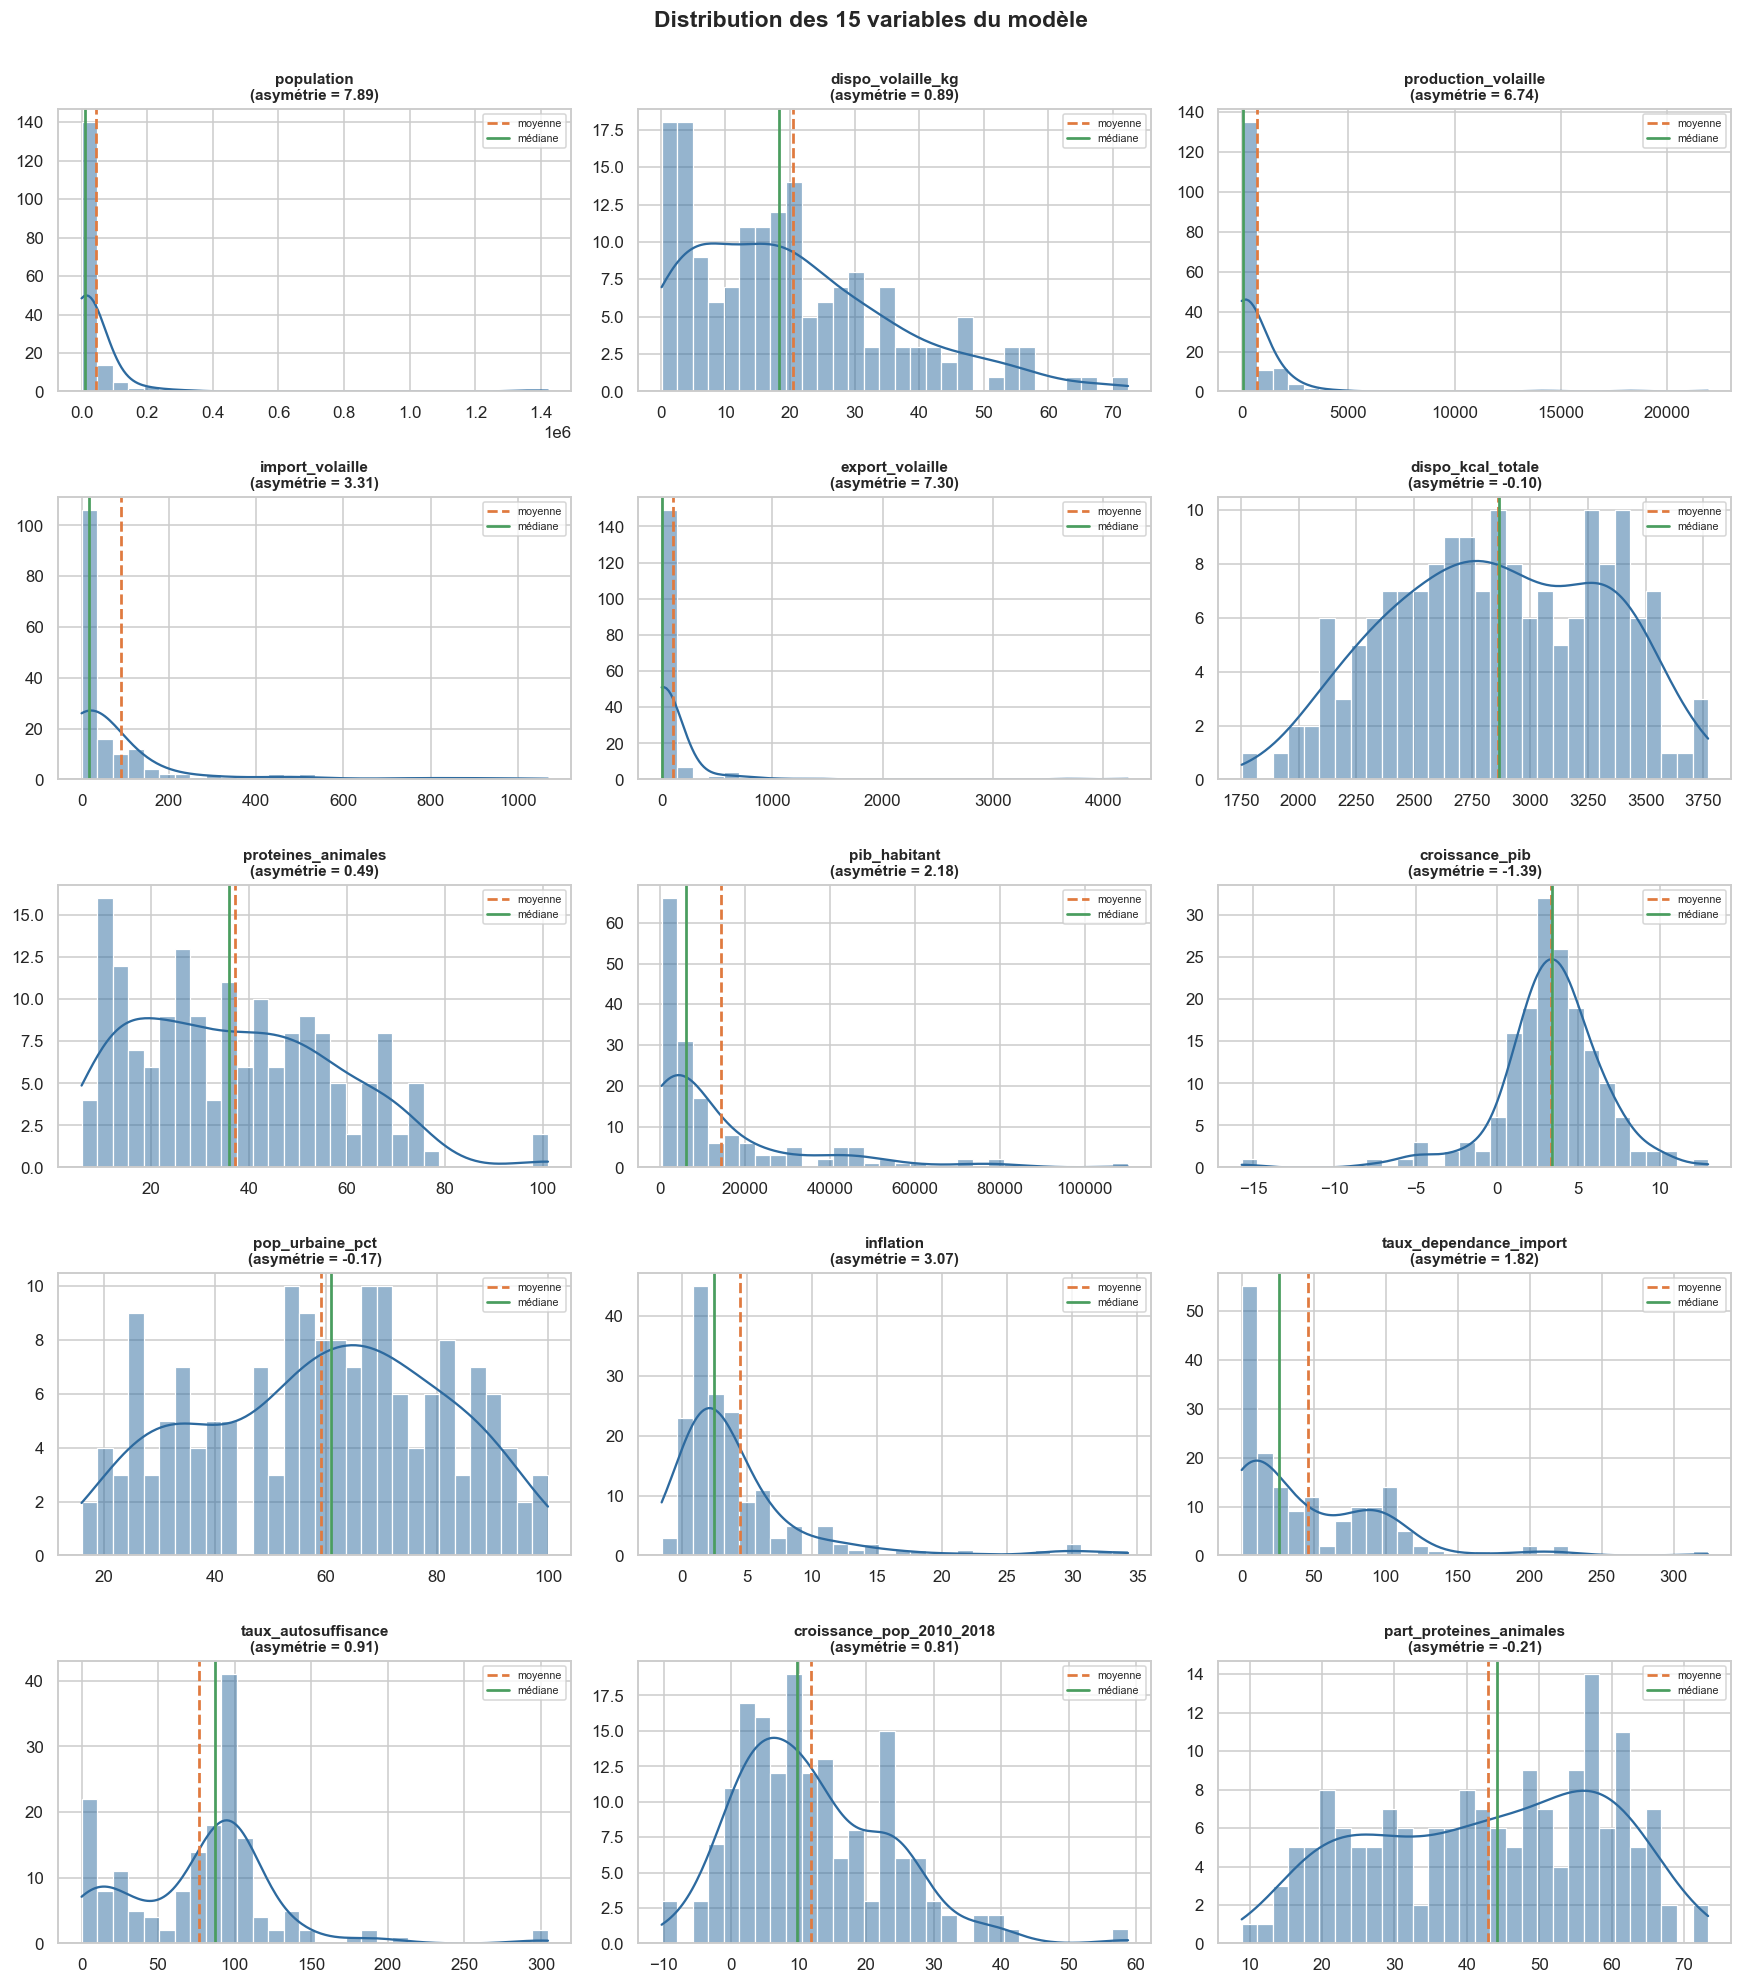

In [126]:
# --- 14.2 Distributions ------------------------------------------------------

n = len(VARS_MODELE)
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
for ax, col in zip(axes.ravel(), VARS_MODELE):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="#2d6a9f", edgecolor="white")
    ax.axvline(df[col].mean(), color="#e07a3f", ls="--", lw=1.8, label="moyenne")
    ax.axvline(df[col].median(), color="#4a9d5f", ls="-", lw=1.8, label="médiane")
    ax.set_title(f"{col}\n(asymétrie = {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.legend(fontsize=7)
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
fig.suptitle("Distribution des 15 variables du modèle", fontsize=15, fontweight="bold", y=1.001)
plt.tight_layout()
plt.show()


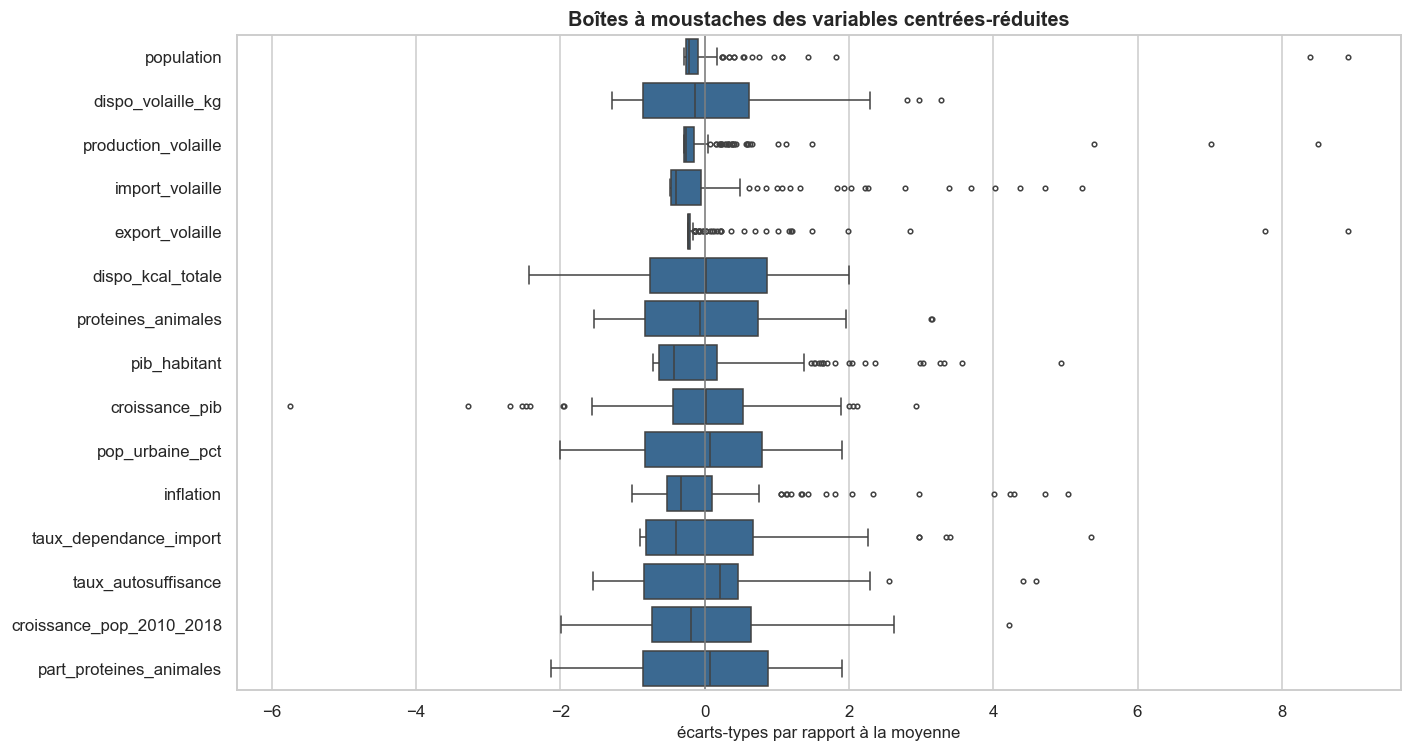

Les variables sont centrées-réduites uniquement pour ce graphique,
afin de les rendre comparables malgré des unités différentes (tonnes, %, USD).


In [127]:
# --- 14.3 Boîtes à moustaches (variables normalisées pour comparaison) -------

from sklearn.preprocessing import StandardScaler

X_std = pd.DataFrame(StandardScaler().fit_transform(df[VARS_MODELE]),
                     columns=VARS_MODELE)

plt.figure(figsize=(13, 7))
sns.boxplot(data=X_std, orient="h", color="#2d6a9f", fliersize=3, linewidth=1)
plt.axvline(0, color="grey", lw=1)
plt.title("Boîtes à moustaches des variables centrées-réduites")
plt.xlabel("écarts-types par rapport à la moyenne")
plt.tight_layout()
plt.show()

print("Les variables sont centrées-réduites uniquement pour ce graphique,")
print("afin de les rendre comparables malgré des unités différentes (tonnes, %, USD).")


---
## 15. Analyse des valeurs extrêmes (outliers)

Une valeur extrême n'est pas nécessairement une erreur. Il faut distinguer :

- l'**erreur de saisie** — à corriger ou supprimer
- la **valeur légitime mais atypique** — la Chine *est* réellement 100 fois plus peuplée
  que la Belgique ; ce n'est pas un bug

On les détecte par la **méthode de Tukey (écart interquartile)**, puis on décide.


In [128]:
# =============================================================================
# 15. VALEURS EXTRÊMES
# =============================================================================

def outliers_tukey(serie, k=1.5):
    """Bornes de Tukey : au-delà de k écarts interquartiles hors des quartiles."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lignes = []
for col in VARS_MODELE:
    bas, haut = outliers_tukey(df[col])
    masque = (df[col] < bas) | (df[col] > haut)
    extremes = df.loc[masque].nlargest(3, col)["pays"].tolist()
    lignes.append({
        "variable": col,
        "borne_basse": round(bas, 1),
        "borne_haute": round(haut, 1),
        "nb_outliers": int(masque.sum()),
        "% du total": round(masque.sum() / len(df) * 100, 1),
        "principaux_pays": ", ".join(extremes),
    })

titre("15.1  DÉTECTION PAR LA MÉTHODE DE TUKEY (1,5 x IQR)")
display(pd.DataFrame(lignes).sort_values("nb_outliers", ascending=False)
          .reset_index(drop=True))


15.1  DÉTECTION PAR LA MÉTHODE DE TUKEY (1,5 x IQR)


,variable,borne_basse,borne_haute,nb_outliers,% du total,principaux_pays
0,export_volaille,-19.50,32.50,34,20.20,"Brésil, États-Unis d'Amérique, Pays-Bas"
1,production_volaille,-521.90,903.10,31,18.50,"États-Unis d'Amérique, Chine, continentale, Br..."
2,import_volaille,-112.10,194.90,19,11.30,"Japon, Mexique, Chine - RAS de Hong-Kong"
3,pib_habitant,"-21,533.00","41,222.50",19,11.30,"Luxembourg, Suisse, Norvège"
4,population,"-38,371.30","71,244.80",18,10.70,"Chine, continentale, Inde, États-Unis d'Amérique"
5,inflation,-4.10,10.50,18,10.70,"Argentine, Soudan, Angola"
6,croissance_pib,-2.90,9.90,12,7.10,"Malte, Guinée, Irlande"
7,taux_dependance_import,-110.90,196.30,5,3.00,"Chine - RAS de Hong-Kong, Belgique, Timor-Leste"
8,dispo_volaille_kg,-27.80,64.70,3,1.80,"Saint-Vincent-et-les Grenadines, Israël, Samoa"
9,taux_autosuffisance,-61.50,196.90,3,1.80,"Belgique, Pays-Bas, Pologne"


In [129]:
# --- 15.2 Qui sont les pays atypiques ? --------------------------------------

compte = pd.Series(0, index=df.index)
for col in VARS_MODELE:
    bas, haut = outliers_tukey(df[col])
    compte += ((df[col] < bas) | (df[col] > haut)).astype(int)

atypiques = (df.assign(nb_variables_extremes=compte)
               [["pays", "continent", "nb_variables_extremes", "population",
                 "pib_habitant", "production_volaille"]]
               .sort_values("nb_variables_extremes", ascending=False)
               .head(15).reset_index(drop=True))

titre("15.2  LES 15 PAYS LES PLUS ATYPIQUES")
display(atypiques)


15.2  LES 15 PAYS LES PLUS ATYPIQUES


,pays,continent,nb_variables_extremes,population,pib_habitant,production_volaille
0,Allemagne,Europe,5,"82,658.41","45,553.93","1,514.00"
1,Pays-Bas,Europe,5,"17,021.35","49,513.68","1,100.00"
2,Belgique,Europe,5,"11,419.75","44,035.32",463.00
3,Chine - RAS de Hong-Kong,Asie,5,"7,306.32","46,160.43",24.00
4,Fédération de Russie,Europe,4,"145,530.08","10,658.91","4,444.00"
5,États-Unis d'Amérique,Amériques,4,"325,084.76","60,047.72","21,914.00"
6,Turquie,Asie,4,"81,116.45","10,756.39","2,192.00"
7,"Chine, continentale",Asie,4,"1,421,021.79","8,979.68","18,236.00"
8,Iran (République islamique d'),Asie,3,"80,673.88","6,000.93","2,174.00"
9,Canada,Amériques,3,"36,732.10","45,129.73","1,417.00"


> ### Décision méthodologique : on **conserve** les valeurs extrêmes
>
> **Pourquoi ?** Ce ne sont pas des erreurs. La Chine produit réellement 20 millions de tonnes
> de volaille ; le Luxembourg a réellement un PIB par habitant de 100 000 USD. Supprimer ces
> pays reviendrait à supprimer une partie de la réalité du marché mondial — et à passer à côté
> de marchés potentiellement majeurs.
>
> **Mais on corrige leur effet de levier.** Sans traitement, ces géants domineraient
> entièrement l'ACP : les premiers axes ne serviraient qu'à séparer la Chine et l'Inde
> du reste du monde, et les 150 autres pays seraient tassés dans un coin du graphique.
>
> **La solution : la transformation logarithmique** des variables très asymétriques.
> Le logarithme comprime les grandes valeurs sans supprimer l'information :
> il transforme un rapport de 1 à 1000 en un rapport de 1 à 3.
> L'ordre des pays est préservé, la hiérarchie aussi, mais les écarts deviennent comparables.
>
> **Attendu en soutenance** : *« Qu'as-tu fait des outliers ? »*
> → *Je les ai identifiés, documentés, et conservés car ils sont légitimes.
> J'ai appliqué une transformation logarithmique aux variables de volume pour éviter
> qu'ils écrasent l'ACP.*


In [130]:
# --- 15.3 Transformation logarithmique des variables très asymétriques -------

SEUIL_ASYM = 2.0
a_transformer = [c for c in VARS_MODELE
                 if df[c].skew() > SEUIL_ASYM and df[c].min() >= 0]

titre(f"15.3  TRANSFORMATION LOG POUR ASYMÉTRIE > {SEUIL_ASYM}")
comparaison = []
for c in a_transformer:
    avant = df[c].skew()
    nouvelle = "log_" + c
    df[nouvelle] = np.log1p(df[c])          # log(1+x) : gère proprement les zéros
    comparaison.append({"variable": c, "asymétrie_avant": round(avant, 2),
                        "asymétrie_après": round(df[nouvelle].skew(), 2),
                        "nouvelle_colonne": nouvelle})

if comparaison:
    display(pd.DataFrame(comparaison))
    print(f"\n{len(a_transformer)} variables transformées.")
    print("np.log1p(x) = log(1+x) : équivalent au logarithme, mais défini en x = 0.")
else:
    print("Aucune variable ne dépasse le seuil d'asymétrie.")

# Jeu de variables retenu pour l'ACP : version log quand elle existe
VARS_ACP = [("log_" + c if "log_" + c in df.columns else c) for c in VARS_MODELE]
print(f"\nVariables retenues pour l'ACP ({len(VARS_ACP)}) :")
for v in VARS_ACP:
    print(f"   • {v}")


15.3  TRANSFORMATION LOG POUR ASYMÉTRIE > 2.0


,variable,asymétrie_avant,asymétrie_après,nouvelle_colonne
0,population,7.89,-0.29,log_population
1,production_volaille,6.74,0.02,log_production_volaille
2,import_volaille,3.31,0.17,log_import_volaille
3,export_volaille,7.30,1.26,log_export_volaille
4,pib_habitant,2.18,0.02,log_pib_habitant



5 variables transformées.
np.log1p(x) = log(1+x) : équivalent au logarithme, mais défini en x = 0.

Variables retenues pour l'ACP (15) :
   • log_population
   • dispo_volaille_kg
   • log_production_volaille
   • log_import_volaille
   • log_export_volaille
   • dispo_kcal_totale
   • proteines_animales
   • log_pib_habitant
   • croissance_pib
   • pop_urbaine_pct
   • inflation
   • taux_dependance_import
   • taux_autosuffisance
   • croissance_pop_2010_2018
   • part_proteines_animales


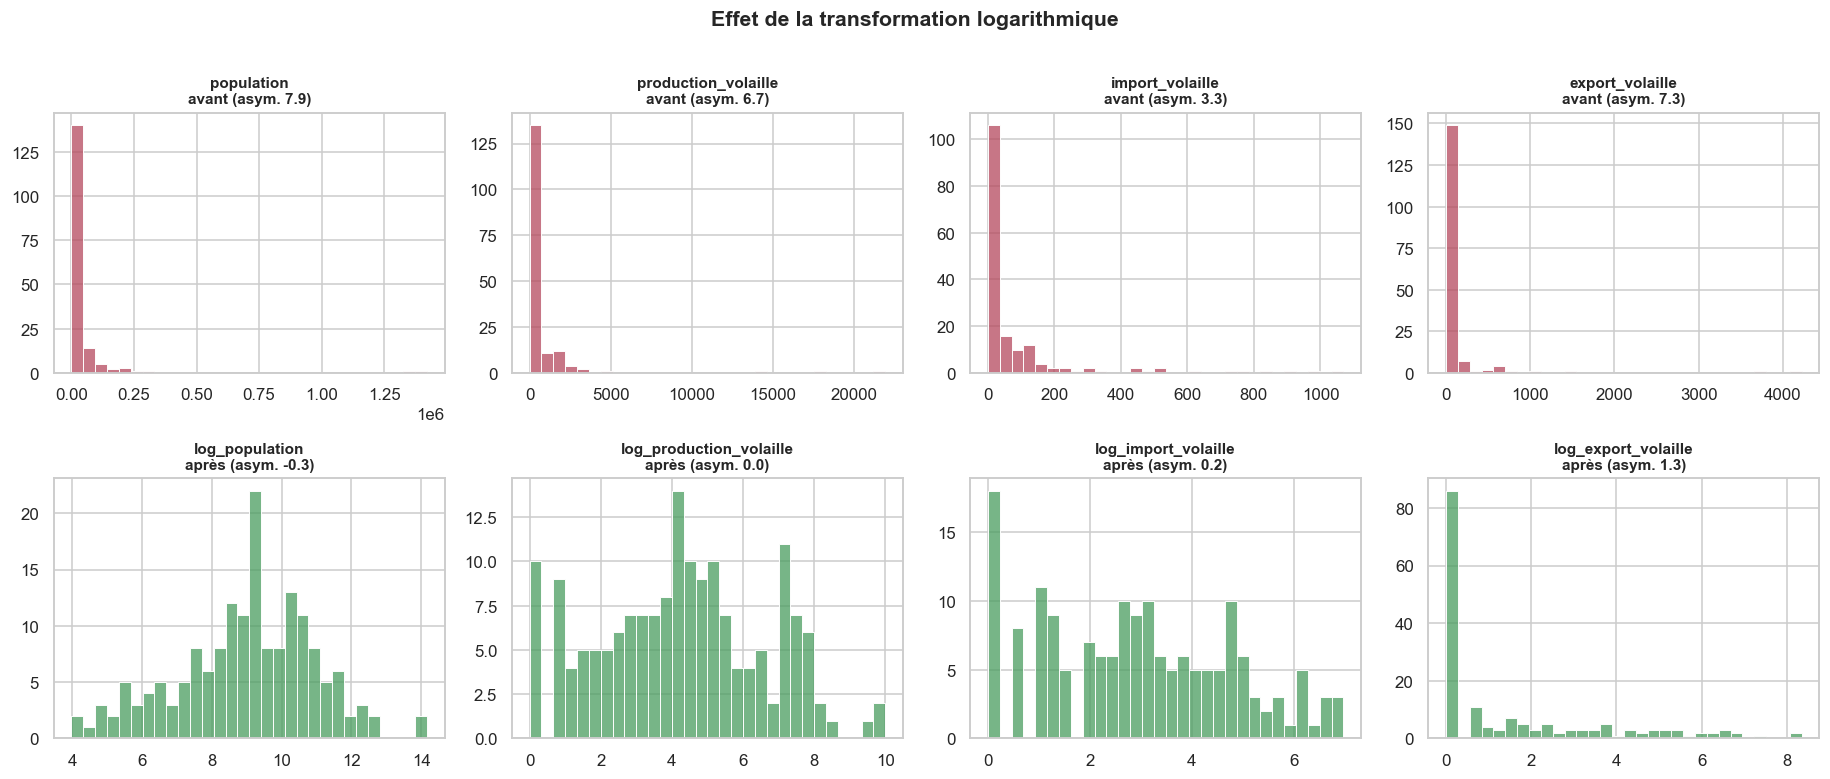

In [131]:
# --- 15.4 Effet visuel de la transformation ----------------------------------

if a_transformer:
    n = min(4, len(a_transformer))
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 7))
    axes = np.atleast_2d(axes)
    for j, c in enumerate(a_transformer[:n]):
        sns.histplot(df[c], bins=30, ax=axes[0, j], color="#b5485d", edgecolor="white")
        axes[0, j].set_title(f"{c}\navant (asym. {df[c].skew():.1f})", fontsize=10)
        sns.histplot(df["log_" + c], bins=30, ax=axes[1, j], color="#4a9d5f", edgecolor="white")
        axes[1, j].set_title(f"log_{c}\naprès (asym. {df['log_'+c].skew():.1f})", fontsize=10)
        for i in (0, 1):
            axes[i, j].set_xlabel(""); axes[i, j].set_ylabel("")
    fig.suptitle("Effet de la transformation logarithmique", fontsize=14,
                 fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()


---
## 16. Analyse bivariée

On étudie maintenant les **relations entre variables**. Deux objectifs :

1. **anticiper l'ACP** — des variables fortement corrélées porteront la même information
   et se regrouperont sur le même axe factoriel
2. **détecter les redondances** — deux variables corrélées à 0,98 font double emploi


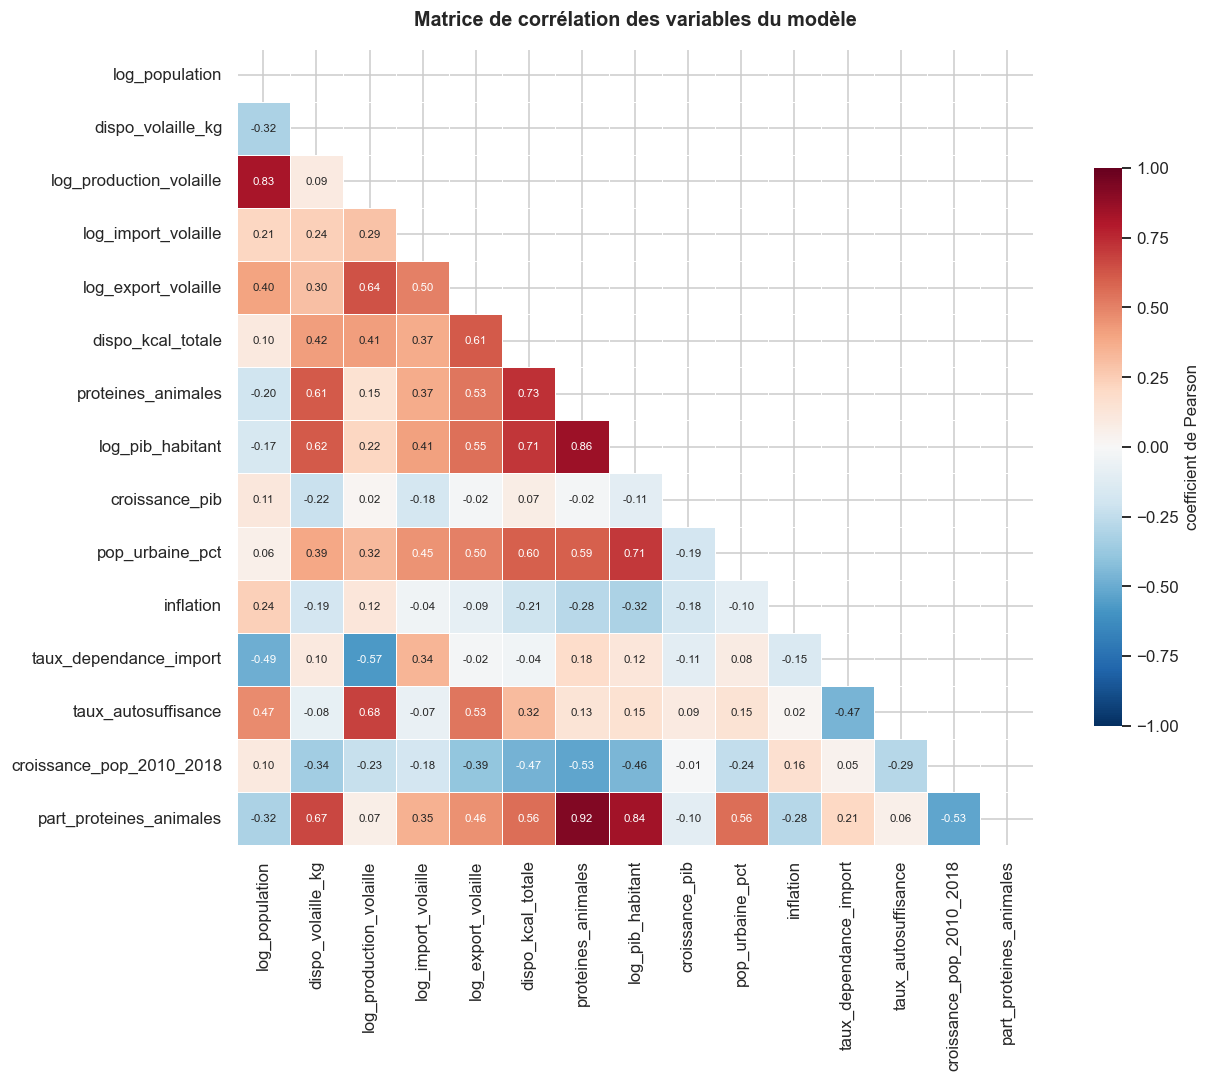

In [132]:
# =============================================================================
# 16. ANALYSE BIVARIÉE
# =============================================================================

corr = df[VARS_ACP].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5,
            annot_kws={"size": 7.5}, cbar_kws={"shrink": .7, "label": "coefficient de Pearson"})
plt.title("Matrice de corrélation des variables du modèle", pad=15)
plt.tight_layout()
plt.show()


In [133]:
# --- 16.2 Les corrélations les plus fortes -----------------------------------

paires = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
              .stack().reset_index())
paires.columns = ["variable_1", "variable_2", "correlation"]
paires["|r|"] = paires["correlation"].abs()

def force(r):
    a = abs(r)
    if a >= 0.8:  return "très forte"
    if a >= 0.6:  return "forte"
    if a >= 0.4:  return "modérée"
    if a >= 0.2:  return "faible"
    return "négligeable"

paires["intensité"] = paires["correlation"].apply(force)
paires["sens"] = np.where(paires["correlation"] > 0, "positive", "négative")

titre("16.2  LES 15 CORRÉLATIONS LES PLUS FORTES")
display(paires.nlargest(15, "|r|")[["variable_1", "variable_2", "correlation",
                                    "intensité", "sens"]].reset_index(drop=True))

redondantes = paires[paires["|r|"] > 0.9]
print(f"\nPaires quasi redondantes (|r| > 0,9) : {len(redondantes)}")
if len(redondantes):
    display(redondantes[["variable_1", "variable_2", "correlation"]])
    print("→ À surveiller : ces variables portent presque la même information.")


16.2  LES 15 CORRÉLATIONS LES PLUS FORTES


,variable_1,variable_2,correlation,intensité,sens
0,proteines_animales,part_proteines_animales,0.92,très forte,positive
1,proteines_animales,log_pib_habitant,0.86,très forte,positive
2,log_pib_habitant,part_proteines_animales,0.84,très forte,positive
3,log_population,log_production_volaille,0.83,très forte,positive
4,dispo_kcal_totale,proteines_animales,0.73,forte,positive
5,dispo_kcal_totale,log_pib_habitant,0.71,forte,positive
6,log_pib_habitant,pop_urbaine_pct,0.71,forte,positive
7,log_production_volaille,taux_autosuffisance,0.68,forte,positive
8,dispo_volaille_kg,part_proteines_animales,0.67,forte,positive
9,log_production_volaille,log_export_volaille,0.64,forte,positive



Paires quasi redondantes (|r| > 0,9) : 1


,variable_1,variable_2,correlation
76,proteines_animales,part_proteines_animales,0.92


→ À surveiller : ces variables portent presque la même information.


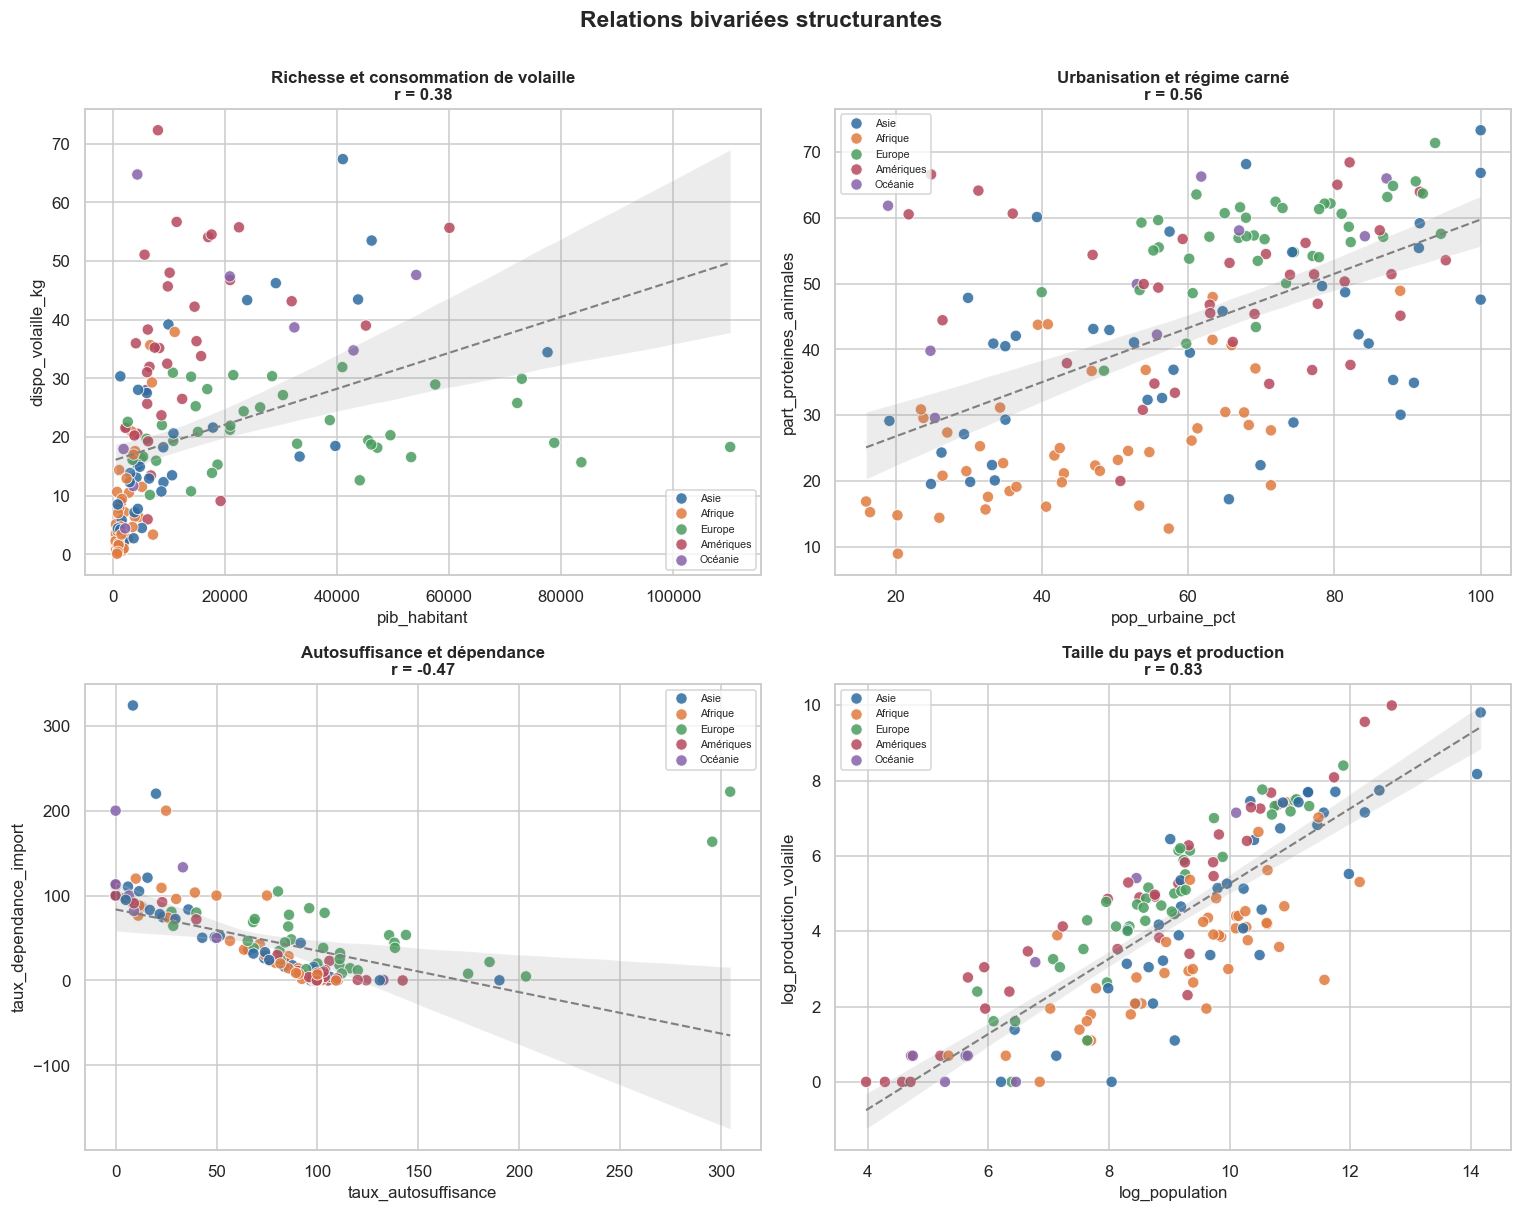

In [134]:
# --- 16.3 Nuages de points sur les relations clés ----------------------------

paires_cles = [
    ("pib_habitant", "dispo_volaille_kg",        "Richesse et consommation de volaille"),
    ("pop_urbaine_pct", "part_proteines_animales", "Urbanisation et régime carné"),
    ("taux_autosuffisance", "taux_dependance_import", "Autosuffisance et dépendance"),
    ("log_population", "log_production_volaille",  "Taille du pays et production"),
]
paires_cles = [(x, y, t) for x, y, t in paires_cles
               if x in df.columns and y in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (x, y, titre_g) in zip(axes.ravel(), paires_cles):
    sns.scatterplot(data=df, x=x, y=y, hue="continent", s=55, alpha=.85,
                    ax=ax, palette=PALETTE[:df["continent"].nunique()])
    sns.regplot(data=df, x=x, y=y, scatter=False, ax=ax,
                color="grey", line_kws={"lw": 1.4, "ls": "--"})
    r = df[[x, y]].corr().iloc[0, 1]
    ax.set_title(f"{titre_g}\nr = {r:.2f}", fontsize=11)
    ax.legend(fontsize=7, title=None)
for ax in axes.ravel()[len(paires_cles):]:
    ax.set_visible(False)
fig.suptitle("Relations bivariées structurantes", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()


16.4  MOYENNES PAR CONTINENT


,dispo_volaille_kg,pib_habitant,taux_dependance_import,pop_urbaine_pct,croissance_pop_2010_2018
continent,,,,,
Afrique,7.90,"2,229.60",40.90,45.30,20.80
Amériques,34.70,"12,464.60",33.60,64.10,8.20
Asie,18.00,"12,333.30",51.10,59.90,15.90
Europe,21.50,"30,698.00",51.50,71.10,1.10
Océanie,32.80,"18,658.80",76.90,53.10,11.50


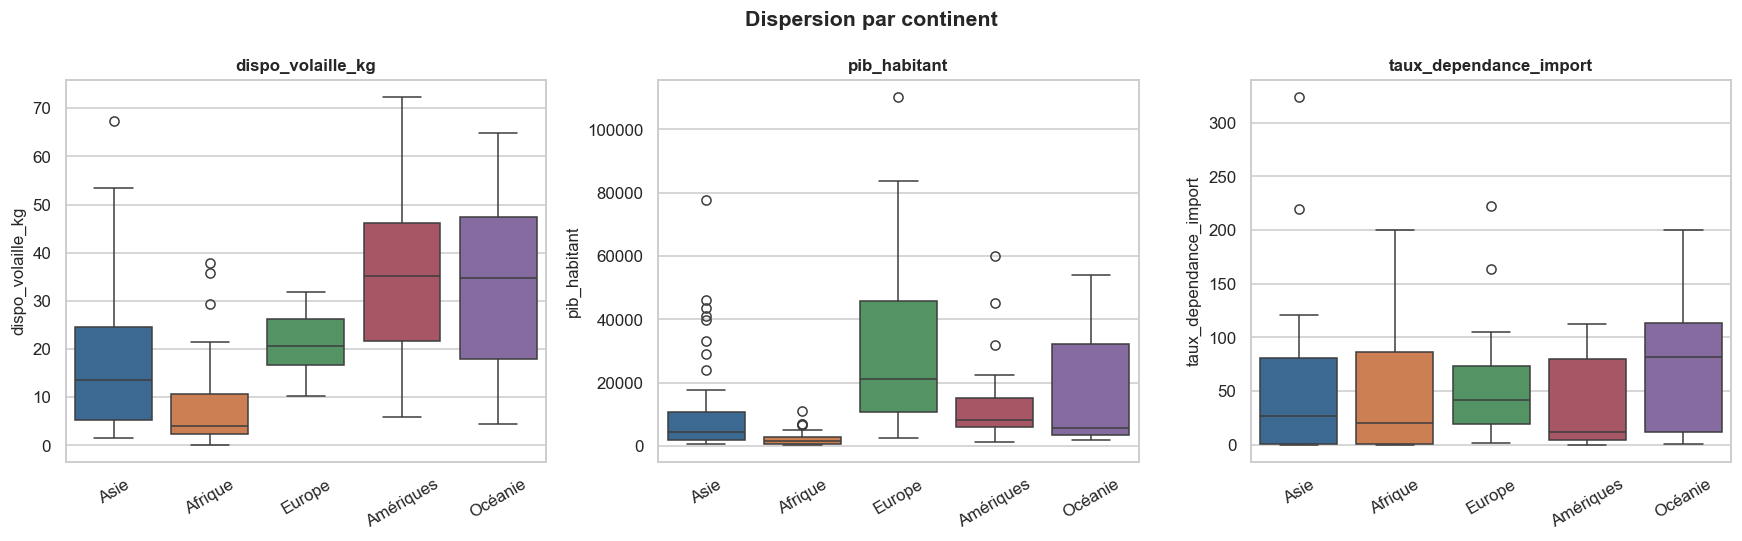

In [135]:
# --- 16.4 Analyse bivariée avec la variable qualitative "continent" ----------

titre("16.4  MOYENNES PAR CONTINENT")
profil = df.groupby("continent")[
    ["dispo_volaille_kg", "pib_habitant", "taux_dependance_import",
     "pop_urbaine_pct", "croissance_pop_2010_2018"]].mean().round(1)
display(profil)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["dispo_volaille_kg", "pib_habitant", "taux_dependance_import"]):
    sns.boxplot(data=df, x="continent", y=col, ax=ax,
                palette=PALETTE[:df["continent"].nunique()], hue="continent", legend=False)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Dispersion par continent", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 17. Export du jeu de données final

Le fichier produit ici est **l'entrée du notebook 2**.


In [136]:
# =============================================================================
# 17. EXPORT
# =============================================================================

COLONNES_FINALES = ["pays", "iso3", "continent"] + VARS_MODELE + \
                   [c for c in df.columns if c.startswith("log_")]
COLONNES_FINALES = list(dict.fromkeys(COLONNES_FINALES))   # dédoublonnage ordonné

df_final = df[COLONNES_FINALES].sort_values("pays").reset_index(drop=True)

chemin = CLEAN + "donnees_pays_2017.csv"
df_final.to_csv(chemin, index=False, encoding="utf-8")

# Dictionnaire des variables, pour la traçabilité
dictionnaire = pd.DataFrame([
    ("pays", "libellé FAO", "texte", "FAO"),
    ("iso3", "code pays ISO 3166-1 alpha-3", "texte", "construit"),
    ("continent", "continent de rattachement", "texte", "construit"),
    ("population", "population totale 2017 (milliers hab.)", "milliers", "FAO"),
    ("dispo_volaille_kg", "disponibilité volaille par habitant", "kg/pers/an", "FAO"),
    ("production_volaille", "production nationale de volaille", "milliers t", "FAO"),
    ("import_volaille", "importations de volaille", "milliers t", "FAO"),
    ("export_volaille", "exportations de volaille", "milliers t", "FAO"),
    ("dispo_kcal_totale", "apport calorique total", "kcal/pers/j", "FAO"),
    ("proteines_animales", "protéines d'origine animale", "g/pers/j", "FAO"),
    ("pib_habitant", "PIB par habitant", "USD courants", "Banque mondiale"),
    ("croissance_pib", "croissance du PIB", "% annuel", "Banque mondiale"),
    ("pop_urbaine_pct", "part de population urbaine", "%", "Banque mondiale"),
    ("inflation", "inflation des prix à la consommation", "% annuel", "Banque mondiale"),
    ("taux_dependance_import", "import / disponibilité intérieure", "%", "CRÉÉE"),
    ("taux_autosuffisance", "production / disponibilité intérieure", "%", "CRÉÉE"),
    ("croissance_pop_2010_2018", "croissance démographique 2010-2018", "%", "CRÉÉE"),
    ("part_proteines_animales", "protéines animales / protéines totales", "%", "CRÉÉE"),
], columns=["variable", "description", "unité", "source"])
dictionnaire.to_csv(CLEAN + "dictionnaire_variables.csv", index=False, encoding="utf-8")

titre("17.  EXPORT RÉALISÉ")
print(f"Fichier principal : {chemin}")
print(f"   {df_final.shape[0]} pays x {df_final.shape[1]} colonnes")
print(f"Dictionnaire      : {CLEAN}dictionnaire_variables.csv")
print(f"\nValeurs manquantes dans le fichier exporté : {int(df_final.isna().sum().sum())}")
print()
display(dictionnaire)


17.  EXPORT RÉALISÉ
Fichier principal : ../Data/clean/donnees_pays_2017.csv
   168 pays x 23 colonnes
Dictionnaire      : ../Data/clean/dictionnaire_variables.csv

Valeurs manquantes dans le fichier exporté : 0



,variable,description,unité,source
0,pays,libellé FAO,texte,FAO
1,iso3,code pays ISO 3166-1 alpha-3,texte,construit
2,continent,continent de rattachement,texte,construit
3,population,population totale 2017 (milliers hab.),milliers,FAO
4,dispo_volaille_kg,disponibilité volaille par habitant,kg/pers/an,FAO
5,production_volaille,production nationale de volaille,milliers t,FAO
6,import_volaille,importations de volaille,milliers t,FAO
7,export_volaille,exportations de volaille,milliers t,FAO
8,dispo_kcal_totale,apport calorique total,kcal/pers/j,FAO
9,proteines_animales,protéines d'origine animale,g/pers/j,FAO


In [137]:
# --- Aperçu du jeu final ------------------------------------------------------
titre("APERÇU DU JEU DE DONNÉES FINAL")
display(df_final.head(10))
print(f"\n{df_final.shape[0]} pays x {df_final.shape[1]} colonnes")


APERÇU DU JEU DE DONNÉES FINAL


,pays,iso3,continent,population,dispo_volaille_kg,production_volaille,import_volaille,export_volaille,dispo_kcal_totale,proteines_animales,pib_habitant,croissance_pib,pop_urbaine_pct,inflation,taux_dependance_import,taux_autosuffisance,croissance_pop_2010_2018,part_proteines_animales,log_population,log_production_volaille,log_import_volaille,log_export_volaille,log_pib_habitant
0,Afghanistan,AFG,Asie,"36,296.11",1.53,28.00,29.00,0.00,"1,997.00",10.56,525.47,2.65,24.84,4.98,50.88,49.12,27.36,19.52,10.50,3.37,3.40,0.00,6.27
1,Afrique du Sud,ZAF,Afrique,"57,009.76",35.69,"1,667.00",514.00,63.00,"2,987.00",34.56,"6,618.34",1.16,63.33,5.19,24.27,78.71,12.84,41.46,10.95,7.42,6.24,4.16,8.80
2,Albanie,ALB,Europe,"2,884.17",16.36,13.00,38.00,0.00,"3,400.00",66.33,"5,006.36",3.28,55.98,1.99,80.85,27.66,-2.21,55.51,7.97,2.64,3.66,0.00,8.52
3,Algérie,DZA,Afrique,"41,389.19",6.38,275.00,2.00,0.00,"3,345.00",25.70,"4,554.67",1.50,71.32,5.59,0.72,99.28,17.37,27.68,10.63,5.62,1.10,0.00,8.42
4,Allemagne,DEU,Europe,"82,658.41",19.47,"1,514.00",842.00,646.00,"3,559.00",63.09,"45,553.93",2.80,80.98,1.51,48.42,87.06,2.84,60.62,11.32,7.32,6.74,6.47,10.73
5,Angola,AGO,Afrique,"29,816.77",10.56,42.00,277.00,0.00,"2,266.00",16.48,"2,832.15",-0.16,65.09,29.84,86.83,13.17,31.91,30.47,10.30,3.76,5.63,0.00,7.95
6,Antigua-et-Barbuda,ATG,Amériques,95.43,54.10,0.00,7.00,0.00,"2,429.00",54.05,"16,965.73",2.71,24.85,2.43,100.00,0.00,9.38,66.61,4.57,0.00,2.08,0.00,9.74
7,Arabie saoudite,SAU,Asie,"33,101.18",43.36,616.00,722.00,10.00,"3,194.00",37.00,"23,929.29",1.18,83.30,-0.83,50.31,42.93,22.91,42.28,10.41,6.42,6.58,2.40,10.08
8,Argentine,ARG,Amériques,"43,937.14",42.24,"2,161.00",8.00,207.00,"3,239.00",65.67,"14,532.50",2.82,91.68,34.28,0.41,110.14,8.47,63.97,10.69,7.68,2.20,5.34,9.58
9,Arménie,ARM,Asie,"2,944.79",16.06,11.00,35.00,0.00,"3,072.00",44.57,"3,869.05",7.50,64.71,0.97,74.47,23.40,2.59,45.79,7.99,2.48,3.58,0.00,8.26



168 pays x 23 colonnes


---
## 18. Synthèse du livrable 1

### Ce qui a été produit

Un fichier `donnees_pays_2017.csv` au format **un pays = une ligne**, sans valeur manquante,
accompagné d'un dictionnaire des variables.

### Démarche suivie

| Étape | Décision et justification |
|---|---|
| **Choix des variables** | grille PESTEL, pour couvrir les 6 dimensions d'un marché plutôt que le seul angle alimentaire |
| **Pivot** | passage du format long au format large, condition nécessaire pour que l'individu statistique soit le pays |
| **Jointure** | par code ISO3 et non par nom de pays, les libellés FAO (français) et Banque mondiale (anglais) étant incompatibles |
| **Agrégats géographiques** | écartés automatiquement, faute de code ISO3 — ce ne sont pas des pays |
| **Flux volaille manquants** | imputés à 0 : l'absence de ligne FAO signifie un flux nul |
| **Indicateurs Banque mondiale manquants** | imputés par la médiane du continent, plus fine que la médiane mondiale |
| **Outliers** | conservés car légitimes, mais effet de levier corrigé par transformation logarithmique |

### Contrôles réglementaires

Tous vérifiés en section 13 : nombre de pays, couverture de la population mondiale,
absence de valeurs manquantes, nombre de variables, variables créées.

### Suite

Le notebook 2 reprend ce fichier pour :
1. réaliser une **ACP** avec réduction de dimensions ;
2. appliquer **deux méthodes de classification** — CAH puis k-means ;
3. comparer les partitions obtenues et formuler des **recommandations de pays**.
